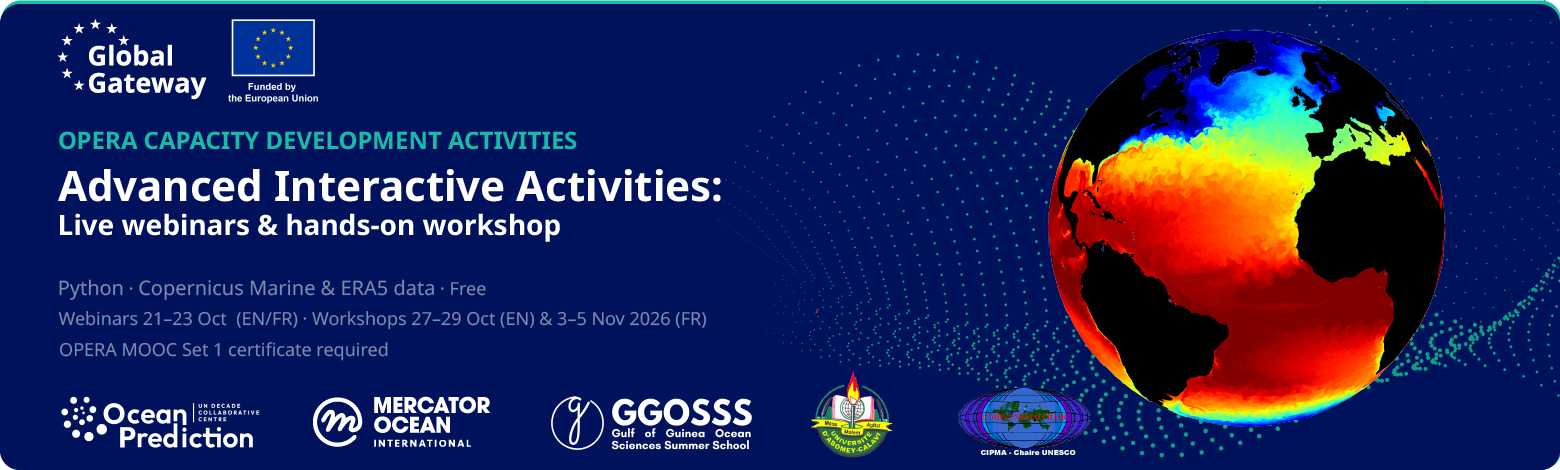

**Content creator:** Babette C. Tchonang

**Content editors:** Badara Sane, Ebenzer Nyadjro, Fernand Assene, Habib Aguedjou & Nathanael Dossa

**Content coordinator:** Arielle Stella Imbol

## About this workshop

This tutorial is part of the [**OPERA Capacity Development**](https://www.unoceanprediction.org/en/ocean-prediction-enhancement-regions-africa-opera) activities, developed and led jointly by [**GGOSSS**](https://www.ggosss.org/) (Gulf of Guinea Ocean Sciences Summer School) and the [**ICMPA – UNESCO Chair**](https://www.icmpa.net/) (International Chair in Mathematical Physics and Applications).

The [OPERA project](https://www.unoceanprediction.org/en/ocean-prediction-enhancement-regions-africa-opera) (*Ocean Prediction Enhancement in Regions of Africa*) is **financed by the [European Union](https://european-union.europa.eu/)** and implemented by [**Mercator Ocean International**](https://www.mercator-ocean.eu/), in the framework of the [**Ocean Prediction Decade Collaborative Centre (OceanPrediction DCC)**](https://www.unoceanprediction.org/).

## Day 1 schedule (09:00–18:00)

| Time | Format | Activity | Notebook |
|------|--------|----------|----------|
| 09:00–09:15 | Opening plenary | Coordinator welcome, housekeeping, team introductions | — |
| 09:15–10:45 | Subgroups | **Setup** — JupyterHub, workspace, packages, the two data accounts | Section 0 |
| 10:45–11:05 | Break | | |
| 11:05–11:50 | Opening plenary | Expert tutorial — **EEOFS Activation** (35 min + 10 min Q&A) | Section 1 |
| 11:50–12:10 | Opening plenary | Study region and the map | Section 2 |
| 12:10–12:30 | Plenary + subgroups | **Copernicus Marine**: guided tour of the website, login | Section 3 |
| 12:30–13:30 | Lunch | | |
| 13:30–15:00 | Plenary + subgroups | Expert demonstration — **four datasets, two services, streamed** (Copernicus Marine and ERA5) | Section 4 |
| 15:00–15:20 | Break | | |
| 15:20–16:20 | Subgroups | Guided practice — inspecting what is inside the cloud datasets | Section 5 |
| 16:20–17:20 | Subgroups | **Independent work** — your own maps and time series | Sections 6–7 |
| 17:20–17:50 | Reconvergence plenary | **First Maps Gallery Walk** | Discussion |
| 17:50–18:00 | Wrap-up plenary | Day 1 checklist, reflection and Day 2 preview | Sections 8–9 |
| *after the workshop* | On your own | **Take it home** — how to download exactly what you used | Section 10 |

### Day 1 learning objectives

1. Reconnect the MOOC concepts (EEOFS, virtuous loop) to practical Copernicus Marine workflows.
2. Navigate the Copernicus Marine website: viewers, product catalogue, documentation, dataset IDs.
3. Understand Copernicus Marine product families: observations, reanalyses, forecasts and hindcasts.
4. **Stream** ocean (Copernicus Marine) and atmosphere (ERA5) data directly into Python, without downloading files.
5. Inspect, map and analyse the data with `xarray`, and know how to download them later if needed.

### How this notebook works

| | Everyone — instructors and participants |
|---|---|
| **All sections** | Run every cell, in order (`Shift + Enter`). **Nothing is downloaded**, so nothing can fill your disk. |
| 🌐 | Do it in your web browser |
| 💻 | Run the code cell |
| ✍️ | Your turn |
| ✋ | Checkpoint — tell your Subgroup Instructor if it did not work |

## Before Day 1

<div style="border-left:6px solid #680000; background:#F4F7FC; padding:10px 14px; margin:8px 0; border-radius:4px"><b style="color:#680000">✋ Before Day 1 — two free accounts (10 minutes, do it before arriving)</b><br>1. <b>Copernicus Marine</b>: <a href='https://data.marine.copernicus.eu/register'>data.marine.copernicus.eu/register</a> — confirm the e-mail you receive.<br>2. <b>DestinE Platform</b> (for ERA5 on the Earth Data Hub): <a href='https://platform.destine.eu/'>platform.destine.eu</a> → register → open the Earth Data Hub page <a href='https://earthdatahub.destine.eu/quota-api-keys#my-personal-access-tokens'>Quota &amp; API keys</a> → copy your default API key (the long text string, not its name <code>edh-bearer</code>).<br>3. Log in once to the workshop JupyterHub: <a href='https://hub.cryointhecloud.com/hub/spawn'>hub.cryointhecloud.com</a>.</div>

## Section 0 — Your workspace on the JupyterHub

<span style="background:#0A2372; color:white; padding:2px 8px; border-radius:4px; font-size:13px">Setup block · 09:15–10:45 · 90 min, everyone hands-on</span>

### Why a JupyterHub in the cloud?

The workshop runs on a **JupyterHub** ([hub.cryointhecloud.com](https://hub.cryointhecloud.com/hub/spawn)): a Jupyter server in the cloud, opened in your web browser.
Everyone has the same software, and the server sits in a data centre with a fast connection to the cloud data stores — much faster than a laptop on a conference Wi-Fi.

**Getting in**

1. 🌐 Open [hub.cryointhecloud.com/hub/spawn](https://hub.cryointhecloud.com/hub/spawn) and sign in.
2. 🌐 Choose the **server option recommended by your instructor**, then *Start*. The first start can take a few minutes.

### What is kept, and what is not

| | On the hub |
|---|---|
| Your **home folder** (`~`): notebooks, figures, credentials | **Kept** between sessions and days |
| Variables in memory (`ds_sst`, monthly fields…) | **Lost** when the server stops (after inactivity) → simply re-run the notebook from the top |
| The ocean and atmosphere data | **Never stored** — they stay in the cloud and are streamed on demand |

### One workspace for the three days

```
~/OPERA_Workshop/
├── Day1/output/      ← every figure and file you produce today
├── Day2/output/      ← Day 2 notebook (DAY = 2)
├── Day3/output/      ← Day 3 notebook (DAY = 3)
└── data/             ← stays EMPTY, unless you choose to download in Section 10
```

In [1]:
# ============================================================
# STEP 0.1 — CREATE YOUR WORKSPACE  (Everyone runs this)
# ─────────────────────────────────────────────────────────────
# One folder per workshop day, each with an output/ subfolder.
# The Day 2 and Day 3 notebooks use the same structure: they
# only change DAY = 2 or DAY = 3.
# ============================================================

from pathlib import Path
import os

DAY          = 1
WORKSHOP_DIR = Path.home() / 'OPERA_Workshop'
OUTPUT_DIR   = WORKSHOP_DIR / f'Day{DAY}' / 'output'
DATA_DIR     = WORKSHOP_DIR / 'data'          # used ONLY if you choose to download (Section 10)

for d in (1, 2, 3):
    (WORKSHOP_DIR / f'Day{d}' / 'output').mkdir(parents=True, exist_ok=True)

print('==> Workspace ready')
print(f'   Workshop folder : ~/{WORKSHOP_DIR.relative_to(Path.home())}')
print(f'   Today\'s outputs : ~/{OUTPUT_DIR.relative_to(Path.home())}')
print()
for d in (1, 2, 3):
    p = WORKSHOP_DIR / f'Day{d}' / 'output'
    n = len(list(p.glob('*')))
    mark = '   <- today' if d == DAY else ''
    print(f'   Day{d}/output   {n:>3} file(s){mark}')

==> Workspace ready
   Workshop folder : ~/OPERA_Workshop
   Today's outputs : ~/OPERA_Workshop/Day1/output

   Day1/output     0 file(s)   <- today
   Day2/output     0 file(s)
   Day3/output     0 file(s)


### Step 0.2 — Install & verify the required packages

<span style="background:#0A2372; color:white; padding:2px 8px; border-radius:4px; font-size:13px">Setup block · 09:15–10:45</span>

| Package | Purpose | MOOC connection |
|---------|---------|----------------|
| `copernicusmarine` | Copernicus Marine Toolbox — catalogue, streaming and downloads | Module 5 — data access |
| `xarray`, `dask` | Labelled N-dimensional arrays, computed lazily and in parallel | Module 5 — gridded data |
| `zarr` (≥ 3), `aiohttp` | Read cloud-optimised **Zarr** stores over the internet (ERA5 on the Earth Data Hub) | Module 5 — data formats |
| `netCDF4`, `h5netcdf` | NetCDF files (only needed if you download, Section 10) | Module 5 — data formats |
| `matplotlib`, `cartopy`, `cmocean` | Plots, maps, oceanographic colour maps | Module 6 — map reading |
| `numpy`, `pandas`, `scipy` | Numerical computing and time series | Modules 2 & 6 |


In [2]:
# ============================================================
# STEP 0.2 — CHECK & INSTALL PACKAGES  (Everyone runs this)
# ─────────────────────────────────────────────────────────────
# Installs what is missing, then VERIFIES with a fresh Python
# what the kernel will load after the restart.
# ============================================================

import importlib, importlib.metadata, subprocess, sys

REQUIRED = [  # (import name, pip requirement)
    ('copernicusmarine', 'copernicusmarine'),
    ('xarray',           'xarray'),
    ('dask',             'dask'),
    ('zarr',             'zarr>=3'),
    ('aiohttp',          'aiohttp'),
    ('netCDF4',          'netCDF4'),
    ('h5netcdf',         'h5netcdf'),
    ('numpy',            'numpy'),
    ('pandas',           'pandas'),
    ('scipy',            'scipy'),
    ('matplotlib',       'matplotlib'),
    ('cartopy',          'cartopy'),
    ('cmocean',          'cmocean'),
]

def fresh_versions(names):
    """Ask a NEW Python process (= the kernel after a restart) which versions it loads."""
    code = ('import importlib, json\nout = {}\n'
            f'for n in {names!r}:\n'
            '    try:\n'
            '        m = importlib.import_module(n); out[n] = [getattr(m, "__version__", "?"), getattr(m, "__file__", "?")]\n'
            '    except Exception as e:\n'
            '        out[n] = ["MISSING", type(e).__name__]\n'
            'print(json.dumps(out))')
    r = subprocess.run([sys.executable, '-c', code], capture_output=True, text=True)
    import json
    return json.loads(r.stdout.strip().splitlines()[-1])

print(f' Python: {sys.executable}\n')
print(' Checking packages...\n')
missing = []
for import_name, requirement in REQUIRED:
    try:
        importlib.import_module(import_name)
        version = importlib.metadata.version(requirement.split('>')[0].split('=')[0])
        if import_name == 'zarr' and int(version.split('.')[0]) < 3:
            print(f'  !!   zarr {version:<12} version 3 or newer is needed to stream ERA5 — will be updated')
            missing.append(requirement)
        else:
            print(f'  ==>  {import_name:<17} {version}')
    except ImportError:
        print(f'  ..   {import_name:<17} not installed yet — will be installed')
        missing.append(requirement)

if not missing:
    print('\n All packages ready — proceed to Step 0.3')
else:
    print(f'\n Installing: {", ".join(missing)} (1–3 minutes)...')
    result = subprocess.run([sys.executable, '-m', 'pip', 'install', '--quiet', '--upgrade', *missing],
                            capture_output=True, text=True)
    if result.returncode != 0:
        print(' ❌  Installation failed — show this message to your Subgroup Instructor:\n')
        print(result.stderr[-1500:])
    else:
        if 'kerchunk' in result.stderr:
            print('      (pip mentions "kerchunk requires zarr<3": harmless — kerchunk is not used in this workshop.)')
        # verify what the kernel WILL load after a restart
        check = fresh_versions([n for n, _ in REQUIRED])
        zv, zfile = check['zarr']
        problems = [n for n, (v, _) in check.items() if v == 'MISSING']
        if zv != 'MISSING' and int(str(zv).split('.')[0]) < 3:
            problems.append(f'zarr is still {zv} ({zfile})')
        if problems:
            print(' ❌  Installed, but a fresh Python still sees a problem:')
            for p in problems:
                print('       -', p)
            print('     Show this to your Subgroup Instructor.')
        else:
            print(f' ==>  Installation verified (zarr {zv}).')
            print('\n==>  RESTART REQUIRED: Kernel -> Restart Kernel, then re-run Steps 0.1 and 0.2')

 Python: /srv/conda/envs/notebook/bin/python

 Checking packages...

  ==>  copernicusmarine  2.5.0
  ==>  xarray            2026.7.0
  ==>  dask              2026.8.0
  ==>  zarr              3.4.1
  ==>  aiohttp           3.14.3
  ==>  netCDF4           1.7.4
  ==>  h5netcdf          1.8.1
  ==>  numpy             2.5.2
  ==>  pandas            2.3.3
  ==>  scipy             1.18.0
  ==>  matplotlib        3.11.1
  ==>  cartopy           0.25.0
  ==>  cmocean           4.0.3

 All packages ready — proceed to Step 0.3


In [3]:
# ============================================================
# STEP 0.3 — IMPORT ALL LIBRARIES  (Everyone runs this)
# ============================================================

import time, shutil, warnings
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import matplotlib.patches as mpatches
import matplotlib.lines as mlines
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import cmocean
import copernicusmarine
from dask.diagnostics import ProgressBar
from IPython.display import display, HTML

warnings.filterwarnings('ignore')
PC = ccrs.PlateCarree()

plt.rcParams.update({'figure.dpi': 100, 'axes.titleweight': 'bold',
                     'axes.titlesize': 12, 'font.size': 10,
                     'axes.titley': 1.02})   # fixed title position: avoids a matplotlib 3.11 + cartopy bug
                                             # that makes maps with gridline labels disappear

# Guard: the kernel must have been restarted after Step 0.2 installed zarr 3
import zarr
if int(zarr.__version__.split('.')[0]) < 3:
    raise RuntimeError(f'zarr {zarr.__version__} is still loaded in this session. '
                       'Kernel -> Restart Kernel, then re-run the notebook from the top (Steps 0.1, 0.2, 0.3...).')

print('==> Libraries imported:')
print(f'   xarray           {xr.__version__}')
print(f'   numpy            {np.__version__}')
print(f'   zarr             {zarr.__version__}')
print(f'   copernicusmarine {copernicusmarine.__version__}')

==> Libraries imported:
   xarray           2026.7.0
   numpy            2.5.2
   zarr             3.4.1
   copernicusmarine 2.5.0


In [4]:
# ============================================================
# STEP 0.4 — HOW MUCH SPACE DO YOU NEED?  (Everyone runs this)
# ─────────────────────────────────────────────────────────────
# Downloading the four datasets would take ~3 GB per region.
# Streaming needs almost nothing: your folder only
# holds notebooks and figures (a few MB).
# ============================================================

total, used, free = shutil.disk_usage(Path.home())
print(f'Home folder disk : {free / 1e9:,.1f} GB free of {total / 1e9:,.1f} GB')

workspace_mb = sum(f.stat().st_size for f in WORKSHOP_DIR.rglob('*') if f.is_file()) / 1e6
print(f'OPERA_Workshop   : {workspace_mb:,.1f} MB used')
print()
print('==> Today the data stay in the cloud: you will not need more than a few MB.')

Home folder disk : 1,110.8 GB free of 6,011.1 GB
OPERA_Workshop   : 0.0 MB used

==> Today the data stay in the cloud: you will not need more than a few MB.


<div style="border-left:6px solid #680000; background:#F4F7FC; padding:10px 14px; margin:8px 0; border-radius:4px"><b style="color:#680000">✋ Checkpoint — end of Section 0</b><br>Step 0.1 shows your three <code>DayN/output</code> folders, Step 0.2 says <i>All packages ready</i> and Step 0.3 prints three versions. If not, raise your hand.</div>

### Plotting helpers

The next cell defines four small tools used by every map today. Run it; you do not need to read it during the session.

In [5]:
# ============================================================
# STEP 0.5 — PLOTTING HELPERS  (Everyone runs this)
# ============================================================

def decorate(ax, extent=None, left=True, bottom=True, land='#C8B99A'):
    """Land, coastline, borders, gridlines — the same style on every map."""
    ax.add_feature(cfeature.LAND,      color=land, zorder=2)
    ax.add_feature(cfeature.COASTLINE, linewidth=0.9, edgecolor='black', zorder=3)
    ax.add_feature(cfeature.BORDERS,   linewidth=0.4, linestyle=':', edgecolor='gray', zorder=3)
    if extent is not None:
        ax.set_extent(extent, crs=PC)
    gl = ax.gridlines(draw_labels=True, linewidth=0.5, color='gray', alpha=0.5, linestyle='--')
    gl.top_labels = gl.right_labels = False
    gl.left_labels, gl.bottom_labels = left, bottom
    return gl


def save_fig(fig, name):
    """Save a figure in today's output folder and say where it went."""
    path = OUTPUT_DIR / name
    fig.savefig(path, dpi=150, bbox_inches='tight')
    print(f'==> Saved: ~/{path.relative_to(Path.home())}')
    return path


def robust_range(da, low=2, high=98, step=0.5):
    """Colour range from the 2nd-98th percentiles, rounded — works for any region."""
    lo, hi = np.nanpercentile(np.asarray(da), [low, high])
    return np.floor(lo / step) * step, np.ceil(hi / step) * step


def arrows(ax, u, v, n_across=20, scale=120, key=5, key_label='5 m s$^{-1}$',
           key_xy=(0.88, 1.03), width=0.0035, color='black'):
    """Quiver plot thinned to ~n_across arrows, with a reference arrow."""
    step = max(1, u.sizes['longitude'] // n_across)
    uq = u.isel(longitude=slice(None, None, step), latitude=slice(None, None, step))
    vq = v.isel(longitude=slice(None, None, step), latitude=slice(None, None, step))
    q = ax.quiver(uq.longitude.values, uq.latitude.values, uq.values, vq.values,
                  transform=PC, scale=scale, width=width, color=color, alpha=0.8, zorder=4)
    ax.quiverkey(q, *key_xy, key, key_label, labelpos='E', coordinates='axes',
                 fontproperties={'size': 9})
    return q

print('==> Helpers ready: decorate(), save_fig(), robust_range(), arrows()')

==> Helpers ready: decorate(), save_fig(), robust_range(), arrows()


---

## Section 1 — EEOFS Activation

<span style="background:#0A2372; color:white; padding:2px 8px; border-radius:4px; font-size:13px">Activation block · 11:05–11:50 · 35 min plenary + 10 min Q&A</span>

### The EEOFS Virtuous Loop

```
  ┌─────────────────────────────────────────────────────────┐
  │  1. OBSERVE ──► 2. ASSIMILATE ──► 3. FORECAST          │
  │       ▲                                  │              │
  │       └──────────── 4. VALIDATE ◄─────────┘              │
  └─────────────────────────────────────────────────────────┘
```

| Step | What happens | CMEMS product used today |
|------|-------------|--------------------------|
| **1. Observe** | Satellites, Argo floats, buoys collect measurements | SSH altimetry, SST L4, surface currents |
| **2. Assimilate** | Observations blended into numerical ocean models | Reanalysis products (gap-free, 1993–present) |
| **3. Forecast** | Model run forward in time | Forecast products (~10-day horizon) |
| **4. Validate** | Forecasts compared to new observations — loop improves | Hindcasts, multi-model ensembles |

### Where our four datasets fit

| Dataset | Loop step | Physical measurement |
|---------|-----------|---------------------|
| **SST L4 Reanalysis** | Observe → Assimilate | Surface temperature from blended satellite obs |
| **SSH Altimetry** | Observe | Sea level from radar altimeter satellites |
| **Surface Currents** | Observe → Assimilate | Velocity derived from altimetry + wind analysis |
| **Wind (ERA5)** | Assimilate | Atmospheric reanalysis — the *forcing* of the ocean |

> **MOOC connections:** Module 1 (EEOFS loop) · Module 4 (observing systems) · Module 5 (CMEMS products)

---

###  Activation Self-Check

*Not graded. Coordinator will ask participants to share answers in chat — move at pace.*

In [6]:
# ============================================================
# EEOFS ACTIVATION SELF-CHECK  (Everyone completes this)
# ─────────────────────────────────────────────────────────────
# Replace each "???" with your answer.
# The Coordinator will ask you to share in the plenary chat.
# ============================================================

Q1 = "Module ???"       # Which MOOC module introduced the EEOFS virtuous loop?
Q2 = "???"              # Which satellite technique measures Sea Surface Height?
Q3 = "???"              # Key difference: reanalysis vs. forecast CMEMS product?
Q4 = "???"              # ONE downstream application relevant to your professional work
Q5 = "???, ???, ???, ???"  # Four variables we stream today (3 ocean + 1 atmosphere)

print('=== EEOFS ACTIVATION ANSWERS ===')
print(f'  Q1 — EEOFS module          : {Q1}')
print(f'  Q2 — SSH satellite method  : {Q2}')
print(f'  Q3 — Reanalysis vs forecast: {Q3}')
print(f'  Q4 — Professional use case : {Q4}')
print(f'  Q5 — Four variables today  : {Q5}')
print()
print(' Share your answers when the Coordinator asks.')

=== EEOFS ACTIVATION ANSWERS ===
  Q1 — EEOFS module          : Module ???
  Q2 — SSH satellite method  : ???
  Q3 — Reanalysis vs forecast: ???
  Q4 — Professional use case : ???
  Q5 — Four variables today  : ???, ???, ???, ???

 Share your answers when the Coordinator asks.


##### Section 2 — The Study Region

<span style="background:#0A2372; color:white; padding:2px 8px; border-radius:4px; font-size:13px">Orientation block · 11:50–12:10 · 20 min</span>

### One region today, three smaller areas later

**Today, everyone works the same region** — the full Gulf of Guinea domain. Same data, same maps, same steps.
That way a problem gets solved once for the whole room.

**On Days 2 and 3 your subgroup takes one smaller area** and analyses it in depth:

| Area | Where | Regime |
|------|-------|--------|
| **1** | Mauritania / Senegal | Eastern boundary upwelling (Canary system) |
| **2** | Gulf of Guinea — eastern part | Equatorial / monsoon, large river outflow |
| **3** | Agulhas, off South Africa | Western boundary current |

Switching is **one line** in the configuration cell. Because the data are streamed, **there is nothing else to download** for Areas 1 and 3.

### Today's domain

**Gulf of Guinea: 10°S–10°N, 10°W–15°E, 2010–2025.** This region matters for West African fisheries, coastal safety,
port operations and climate services — and it contains several distinct processes in one box: coastal upwelling,
equatorial dynamics and major river outflow.

The cell below sets the domain and the analysis period. **Every dataset, map and time series in this notebook reads from it.**

<div style="border-left:6px solid #1A54EB; background:#F4F7FC; padding:10px 14px; margin:8px 0; border-radius:4px"><b style="color:#1A54EB">LIGHT_MODE — if the connection is slow</b><br>Set <code>LIGHT_MODE = True</code>: the analysis uses <b>2020–2025</b> instead of 2010–2023, so about three times less data travels. Everything else works the same.</div>

In [7]:
# ============================================================
# TWO-PHASE DOMAIN CONFIGURATION
# ─────────────────────────────────────────────────────────────
# PHASE 1 (plenary)  — EVERYONE works the same big Gulf of
#                      Guinea domain. Same maps, same steps,
#                      shared vocabulary.
# PHASE 2 (subgroup) — each subgroup narrows to ONE smaller
#                      study area, on Days 2 and 3.
#
# The data are STREAMED from the cloud, so any box works at once:
# switching zone is one line, and nothing has to be downloaded.
#
# VERIFY these boxes before the workshop.
# ============================================================

# ---------- PHASE 1: the shared teaching domain ----------
SHARED = dict(
    name   = 'Gulf of Guinea (shared domain)',
    prefix = 'GOG',
    lon    = (-10.0, 15.0),
    lat    = ( -10.0, 10.0),
)

# ---------- PHASE 2: the three subgroup study areas ----------
ZONES = {
    '1': dict(
        name        = 'Mauritania / Senegal',
        prefix      = 'MRS',              # used in figure file names
        lon         = (-21.0, -15.0),
        lat         = ( 14.0,  25.0),
        regime      = 'Canary Eastern Boundary Upwelling System',
        wind_story  = 'Alongshore NE trades drive offshore Ekman transport '
                      '-> strong coastal upwelling',
        sst_range   = (16, 26), sst_snap = (15, 25), ts_ylim = (14, 30),
        hemisphere  = 'N', upwell_season = 'JJA',
        ref_points  = [(-17.0, 21.0, 'Nouadhibou  (Mauritania)'),
                       (-16.6, 19.0, 'Nouakchott  (Mauritania)'),
                       (-17.5, 14.7, 'Dakar  (Senegal)')],
    ),
    '2': dict(
        name        = 'Gulf of Guinea',
        prefix      = 'GOG',              # a slice of the shared domain
        lon         = (  5.0, 15.0),      # narrowed for subgroup work
        lat         = ( -5.0,  5.0),
        regime      = 'Equatorial / monsoon, large river outflow',
        wind_story  = 'Monsoon southwesterlies; Coriolis vanishes at the '
                      'equator, so Ekman theory breaks down here',
        sst_range   = (24, 29), sst_snap = (22, 29), ts_ylim = (19, 33),
        hemisphere  = 'N', upwell_season = 'JJA',
        ref_points  = [( 6.0,  3.5, 'Bight of Biafra'),
                       ( 9.5,  1.0, 'Port-Gentil  (Gabon)'),
                       (12.0, -4.5, 'Pointe-Noire  (Congo)')],
    ),
    '3': dict(
        name        = 'Agulhas',
        prefix      = 'AGU',              # used in figure file names
        lon         = ( 15.0,  30.0),
        lat         = (-38.0, -30.0),
        regime      = 'Western boundary current — rings, marine heatwaves',
        wind_story  = 'Westerlies are strong, but this current is inertial: '
                      'wind is NOT the local driver',
        sst_range   = (14, 24), sst_snap = (12, 24), ts_ylim = (12, 28),
        hemisphere  = 'S', upwell_season = 'DJF',
        ref_points  = [(18.3, -34.4, 'Cape Point  (South Africa)'),
                       (22.5, -34.8, 'Mossel Bay  (South Africa)'),
                       (27.5, -33.4, 'Port Edward  (South Africa)')],
    ),
}

# ─────────────────────────────────────────────────────────────
# PHASE — 'shared' for the plenary, 'zone' for subgroup work
# ZONE  — your subgroup: '1', '2' or '3'
# ─────────────────────────────────────────────────────────────
PHASE       = 'shared'     # <- switch to 'zone' when subgroup work starts
ACTIVE_ZONE = '2'          # <- '1', '2' or '3'

Z = ZONES[ACTIVE_ZONE]
D = SHARED if PHASE == 'shared' else Z

LON_MIN, LON_MAX = D['lon']
LAT_MIN, LAT_MAX = D['lat']
DOMAIN_NAME      = D['name']
FILE_PREFIX      = D['prefix']

# Plot styling always follows the ZONE, so colour scales stay
# sensible whichever phase you are in.
SST_VMIN,  SST_VMAX  = Z['sst_range']
SNAP_VMIN, SNAP_VMAX = Z['sst_snap']
TS_YMIN,   TS_YMAX   = Z['ts_ylim']
ZONE_NAME  = Z['name']
REF_POINTS = Z['ref_points'] if PHASE == 'zone' else [
    (-3.5, 5.0, 'Abidjan / Accra'), (2.5, 6.0, 'Cotonou'), (9.5, 1.0, 'Port-Gentil')]

# Same box in the format of the Copernicus Marine Toolbox
BOX = dict(minimum_longitude=LON_MIN, maximum_longitude=LON_MAX,
           minimum_latitude=LAT_MIN,  maximum_latitude=LAT_MAX)

DATE_START = '2010-01-01'
DATE_END   = '2025-12-31'

LIGHT_MODE = False          # True = 2019-2023 only (slow connection)
if LIGHT_MODE:
    DATE_START = '2020-01-01'
PERIOD = f'{DATE_START[:4]}–{DATE_END[:4]}'

# Day used for the SST snapshot (Map 3): mid-August, peak of the
# boreal upwelling season. Kept inside the analysis period.
SNAP_DATE = '2015-08-15'
if not (DATE_START <= SNAP_DATE <= DATE_END):
    SNAP_DATE = f'{DATE_START[:4]}-08-15'

COLORS = ['#E74C3C', '#27AE60', '#8E44AD']

print(f'==> PHASE = {PHASE.upper()}')
print(f'   Domain : {DOMAIN_NAME}')
print(f'   Box    : lon [{LON_MIN}, {LON_MAX}]   lat [{LAT_MIN}, {LAT_MAX}]')
print(f'   Prefix : {FILE_PREFIX}  (figure file names)')
print(f'   Period : {DATE_START} -> {DATE_END}' + ('   (LIGHT_MODE)' if LIGHT_MODE else ''))
print(f'   Snapshot day : {SNAP_DATE}')
print()
print(f'==> Your subgroup zone: {ACTIVE_ZONE} — {Z["name"]}')
print(f'   Regime : {Z["regime"]}')
print(f'   Wind   : {Z["wind_story"]}')
if Z['hemisphere'] == 'S':
    print()
    print('   !! SOUTHERN HEMISPHERE — seasons are reversed.')
    print('      JJA is WINTER here, DJF is SUMMER.')
print()
print('==> All zones')
for k, z in ZONES.items():
    mark = '  <- yours' if k == ACTIVE_ZONE else ''
    src  = 'slice of the shared domain' if z['prefix'] == SHARED['prefix'] else 'separate box, streamed'
    print(f'   Zone {k}  {z["name"]:<22} {src:<24}{mark}')


==> PHASE = SHARED
   Domain : Gulf of Guinea (shared domain)
   Box    : lon [-10.0, 15.0]   lat [-10.0, 10.0]
   Prefix : GOG  (figure file names)
   Period : 2010-01-01 -> 2025-12-31
   Snapshot day : 2015-08-15

==> Your subgroup zone: 2 — Gulf of Guinea
   Regime : Equatorial / monsoon, large river outflow
   Wind   : Monsoon southwesterlies; Coriolis vanishes at the equator, so Ekman theory breaks down here

==> All zones
   Zone 1  Mauritania / Senegal   separate box, streamed  
   Zone 2  Gulf of Guinea         slice of the shared domain  <- yours
   Zone 3  Agulhas                separate box, streamed  


==> Saved: ~/OPERA_Workshop/Day1/output/Day1_study_region_map.png


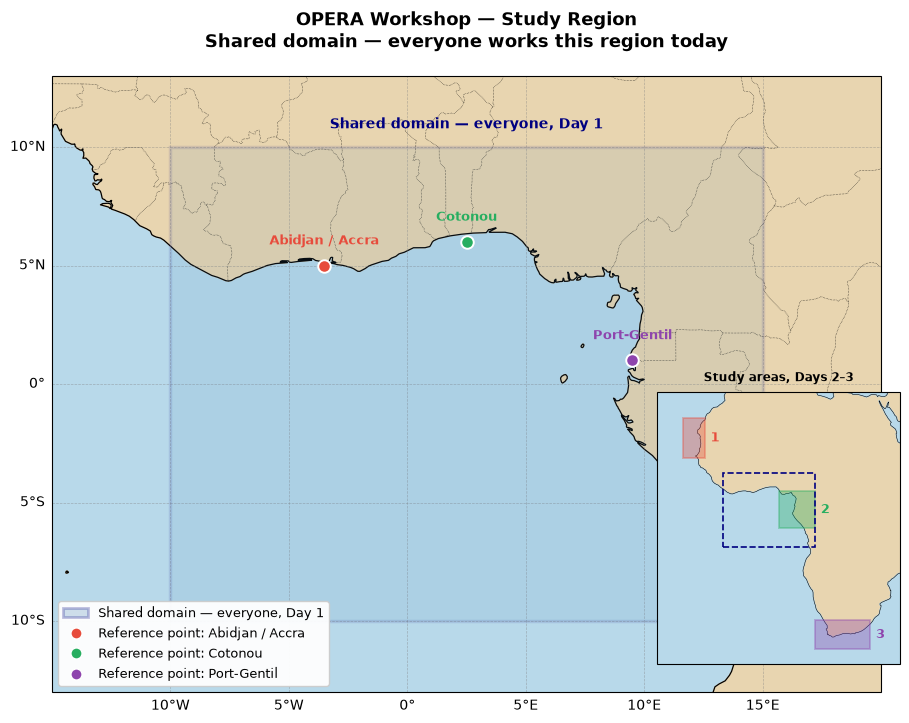


   Main map : Shared domain — everyone, Day 1
   Inset    : 1 Mauritania/Senegal   2 Gulf of Guinea   3 Agulhas
              (dashed navy = the shared domain you are working today)


In [8]:
# ============================================================
# VISUALIZE THE STUDY REGION
# ─────────────────────────────────────────────────────────────
# Adapts to PHASE:
#   'shared' -> the full Gulf of Guinea download domain (Day 1)
#   'zone'   -> your own study area (Days 2-3)
# The inset shows where all three study areas sit on the
# continent, so you can see where yours is relative to today's.
# ============================================================

fig = plt.figure(figsize=(12, 8))
ax  = fig.add_subplot(1, 1, 1, projection=ccrs.PlateCarree())
ax.set_extent([LON_MIN - 5, LON_MAX + 5, LAT_MIN - 3, LAT_MAX + 3],
              crs=ccrs.PlateCarree())

ax.add_feature(cfeature.LAND,      color='#E8D5B0', zorder=1)
ax.add_feature(cfeature.OCEAN,     color='#B8D9EA', zorder=0)
ax.add_feature(cfeature.COASTLINE, linewidth=0.9, zorder=2)
ax.add_feature(cfeature.BORDERS,   linewidth=0.4, linestyle=':', zorder=2)

# ---- the box we are actually working in ----
box_label = ('Shared domain — everyone, Day 1' if PHASE == 'shared'
             else f'Area {ACTIVE_ZONE} — {ZONE_NAME}')
ax.add_patch(mpatches.Rectangle(
    (LON_MIN, LAT_MIN), LON_MAX - LON_MIN, LAT_MAX - LAT_MIN,
    linewidth=2.5, edgecolor='navy', facecolor='steelblue', alpha=0.10,
    transform=ccrs.PlateCarree(), zorder=3))
ax.text((LON_MIN + LON_MAX) / 2, LAT_MAX + 0.8, box_label,
        ha='center', fontsize=10, color='navy', fontweight='bold',
        transform=ccrs.PlateCarree())

# ---- coastal reference points (these are PLACES, not areas) ----
colors  = ['#E74C3C', '#27AE60', '#8E44AD']
handles = [mpatches.Patch(edgecolor='navy', facecolor='steelblue',
                          alpha=0.25, lw=2, label=box_label)]

for (rlon, rlat, rname), color in zip(REF_POINTS, colors):
    label = rname.split('(')[0].strip()
    ax.plot(rlon, rlat, marker='o', markersize=9, color=color,
            markeredgecolor='white', markeredgewidth=1.4,
            transform=ccrs.PlateCarree(), zorder=6)
    ax.text(rlon, rlat + (LAT_MAX - LAT_MIN) * 0.045, label,
            ha='center', fontsize=9, fontweight='bold', color=color,
            transform=ccrs.PlateCarree(), zorder=6)
    handles.append(mlines.Line2D([], [], color=color, marker='o', linestyle='None',
                                 markersize=8, markeredgecolor='white',
                                 label=f'Reference point: {label}'))

gl = ax.gridlines(draw_labels=True, linewidth=0.5, color='gray',
                  alpha=0.5, linestyle='--')
gl.top_labels = False; gl.right_labels = False
gl.xlocator = mticker.FixedLocator(np.arange(np.floor(LON_MIN/5)*5, LON_MAX + 6, 5))
gl.ylocator = mticker.FixedLocator(np.arange(np.floor(LAT_MIN/5)*5, LAT_MAX + 6, 5))

subtitle = ('Shared domain — everyone works this region today'
            if PHASE == 'shared'
            else Z['regime'])
ax.set_title(f'OPERA Workshop — Study Region\n{subtitle}',
             fontsize=13, fontweight='bold', pad=12)
ax.legend(handles=handles, loc='lower left', fontsize=9, framealpha=0.95)

# ---- inset: where the three study areas are on the continent ----
inset = fig.add_axes([0.655, 0.145, 0.235, 0.34], projection=ccrs.PlateCarree())
inset.set_extent([-28, 38, -42, 32], crs=ccrs.PlateCarree())
inset.add_feature(cfeature.LAND,      color='#E8D5B0')
inset.add_feature(cfeature.OCEAN,     color='#B8D9EA')
inset.add_feature(cfeature.COASTLINE, linewidth=0.4)

area_cols = {'1': '#E74C3C', '2': '#27AE60', '3': '#8E44AD'}
for k, z in ZONES.items():
    lo0, lo1 = z['lon']; la0, la1 = z['lat']
    inset.add_patch(mpatches.Rectangle(
        (lo0, la0), lo1 - lo0, la1 - la0,
        linewidth=1.4, edgecolor=area_cols[k],
        facecolor=area_cols[k], alpha=0.35,
        transform=ccrs.PlateCarree(), zorder=4))
    inset.text(lo1 + 1.5, (la0 + la1) / 2, k, fontsize=9, fontweight='bold',
               color=area_cols[k], va='center', transform=ccrs.PlateCarree())

# today's shared domain, dashed, for reference
inset.add_patch(mpatches.Rectangle(
    (SHARED['lon'][0], SHARED['lat'][0]),
    SHARED['lon'][1] - SHARED['lon'][0],
    SHARED['lat'][1] - SHARED['lat'][0],
    linewidth=1.2, edgecolor='navy', facecolor='none', linestyle='--',
    transform=ccrs.PlateCarree(), zorder=5))

inset.set_title('Study areas, Days 2–3', fontsize=8.5, fontweight='bold', pad=4)

save_fig(fig, 'Day1_study_region_map.png')
plt.show()
print()
print(f'   Main map : {box_label}')
print( '   Inset    : 1 Mauritania/Senegal   2 Gulf of Guinea   3 Agulhas')
print( '              (dashed navy = the shared domain you are working today)')


## Section 3 — The Copernicus Marine Service: guided tour and login

<span style="background:#0A2372; color:white; padding:2px 8px; border-radius:4px; font-size:13px">Access block · 12:10–12:30 · 20 min, everyone follows in the browser</span>

The [Copernicus Marine Service](https://marine.copernicus.eu/) is the marine component of the EU Copernicus programme, implemented by
Mercator Ocean International. It provides **free and open** information on the **blue** (physics), **white** (sea ice) and **green**
(biogeochemistry) ocean: observations (satellite and in situ), analyses and forecasts, and reanalyses covering several decades.
It is the operational end of everything Module 1 described as the EEOFS.

<div style="border-left:6px solid #6B7280; background:#F4F7FC; padding:10px 14px; margin:8px 0; border-radius:4px"><b style="color:#6B7280">⚠️ Set expectations for Africa</b><br>Copernicus Marine has global products and regional products for European seas. There is <b>no dedicated West African regional product</b>: for African coasts we use the <b>global</b> products (1/12° ≈ 9 km for model physics). This is exactly the gap that regional systems such as SEA-FORWARD address by downscaling.</div>

### 3.1 The viewer ladder — from discovery to expert queries 🌐

Everyone follows on screen. Tick each step when done.

| Step | Tool | What to do | Time |
|---|---|---|---|
| ☐ 1 | [**MyOcean Light**](https://data.marine.copernicus.eu/viewer) | Zoom on **your coastline**. Display today's sea surface temperature; move the time slider back one month. | 4 min |
| ☐ 2 | [**MyOcean Pro**](https://data.marine.copernicus.eu/viewer/expert) | Add *Global Ocean Physics Analysis and Forecast*. Click a point offshore of your city and plot its **time series**. | 4 min |
| ☐ 3 | [**Product catalogue**](https://data.marine.copernicus.eu/products) | Search `SEALEVEL_GLO_PHY_L4_MY_008_047` — the sea-level product we use today. | 4 min |

### 3.2 Reading a product page 🌐

On the page of `SEALEVEL_GLO_PHY_L4_MY_008_047`, find:

- ☐ the **product ID** and its **dataset IDs** (tab *Data access*) — there is a **daily** and a **monthly** dataset. We use the **daily** one and build monthly means ourselves;
- ☐ the spatial resolution, the time coverage and the update frequency;
- ☐ the **Product User Manual (PUM)** and the **Quality Information Document (QUID)** — *read the documentation before using a product, not after a result looks strange*;
- ☐ the **DOI** to cite the product in a report or paper.

<div style="border-left:6px solid #1A54EB; background:#F4F7FC; padding:10px 14px; margin:8px 0; border-radius:4px"><b style="color:#1A54EB">💡 The Data Store writes the code for you</b><br>Open a dataset → <b>Subset</b>: choose the variables, the area and the period → the <b>Automate</b> option shows the matching Copernicus Marine Toolbox command. Today we use exactly the same parameters in Python, with <code>open_dataset()</code> instead of downloading.</div>

### 3.3 Decoding a dataset ID

`cmems_obs-sl_glo_phy-ssh_my_allsat-l4-duacs-0.125deg_P1D`

| Part | Meaning | Other values you will meet |
|---|---|---|
| `cmems` | Copernicus Marine | |
| `obs` | observations | `mod` model output |
| `sl` | sea level (thematic centre) | `mob` multi-observation, `wind`, `oc` ocean colour |
| `glo` | global domain | `ibi`, `med`, `bal`, `nws`, `arc`, `blk` regional seas |
| `phy-ssh` | physics · sea surface height | `phy-cur` currents, `phy-thetao` temperature |
| `my` | **m**ulti-**y**ear (reprocessed, for climate and reanalysis work) | `anfc`/`nrt` near real time |
| `allsat-l4-duacs` | all satellites, Level 4 (gap-filled maps), DUACS processing | `l3` along-track |
| `0.125deg` | 1/8° grid (≈ 14 km) | `0.25deg`, `0.083deg` |
| `P1D` | **daily** fields (period 1 day) | `P1M-m` monthly means, `PT1H-i` hourly instantaneous |

<div style="border-left:6px solid #680000; background:#F4F7FC; padding:10px 14px; margin:8px 0; border-radius:4px"><b style="color:#680000">✋ Checkpoint (2 min)</b><br>In the catalogue, open <code>MULTIOBS_GLO_PHY_MYNRT_015_003</code> (surface currents). What is the dataset ID of its <b>daily multi-year</b> dataset? <details><summary>Answer</summary><code>cmems_obs-mob_glo_phy-cur_my_0.25deg_P1D-m</code> — daily means, 1/4°, surface and 15 m.</details></div>

**Help when you need it:** [Help Centre](https://help.marine.copernicus.eu/en/) (articles and live chat) ·
[Copernicus Marine Toolbox documentation](https://toolbox-docs.marine.copernicus.eu/) ·
[Ocean Monitoring Indicators](https://marine.copernicus.eu/access-data/ocean-monitoring-indicators) ·
[User learning services](https://marine.copernicus.eu/services/user-learning-services).

### 3.4 Log in from Python (once)

The cell **checks first** whether valid credentials already exist, and only prompts if they do not.
`login(check_credentials_valid=True)` returns `True` or `False` without prompting. Once you log in, the credentials are stored in
`~/.copernicusmarine/` in **your home folder on the hub** — so it is once for the whole workshop.

> 🔒 **Security rule:** never type your password inside a code cell. The cell below asks for it with a hidden prompt.

| Role | Action |
|------|--------|
| **Everyone** | Run the cell. Streaming needs every participant to be logged in. |

In [16]:
# ============================================================
# STEP 3.4 — COPERNICUS MARINE LOGIN  (Everyone runs this)
# ─────────────────────────────────────────────────────────────
# login(check_credentials_valid=True) returns True/False WITHOUT
# prompting. It looks in this order and stops at the first hit:
#     1. username / password passed directly
#     2. COPERNICUSMARINE_SERVICE_USERNAME / _PASSWORD env vars
#     3. the stored credentials file (~/.copernicusmarine/)
# ============================================================

from getpass import getpass

def cmems_ready():
    """True if usable Copernicus Marine credentials already exist. Never prompts."""
    try:
        return bool(copernicusmarine.login(check_credentials_valid=True))
    except Exception as e:
        print(f'   could not check credentials: {type(e).__name__}: {e}')
        return False

print('Checking for existing Copernicus Marine credentials...\n')

if cmems_ready():
    print('   ==> Already logged in. Credentials valid — nothing to do.')
else:
    print('   No valid credentials found. Enter your Copernicus Marine username and password.')
    username = input('   Copernicus Marine username: ').strip()
    password = getpass('   Copernicus Marine password: ')
    copernicusmarine.login(username=username, password=password, force_overwrite=True)
    del password
    print()
    if cmems_ready():
        print('   ==> Login successful, credentials verified and stored for the workshop.')
    else:
        print('   ==> Login did NOT verify. Common causes:')
        print('       - typo in username or password')
        print('       - e-mail address not yet confirmed after registering')
        print('       Register or reset at https://data.marine.copernicus.eu/register')

INFO - 2026-10-27T13:59:37Z - Checking if credentials are valid.


Checking for existing Copernicus Marine credentials...



INFO - 2026-10-27T13:59:37Z - Valid credentials from configuration file.


   ==> Already logged in. Credentials valid — nothing to do.


### 3.5 The second service: ERA5 on the Earth Data Hub

Wind is where Module 2 comes back: **wind is the main dynamic forcing over the ocean**. The ocean datasets come from
Copernicus Marine; the wind comes from **ERA5**, the atmospheric reanalysis produced by ECMWF for the Copernicus Climate Change Service —
the same kind of product used to **force ocean models**, including many Copernicus Marine products.

ERA5 is officially distributed by the **Climate Data Store (CDS)**, which **queues** requests and delivers files.
To **stream** ERA5 instead, we use the **Earth Data Hub** of the EU **Destination Earth (DestinE)** platform: a cloud-optimised
**Zarr** mirror of the same ERA5 datasets, opened directly with `xarray`.

| | Copernicus Marine | ERA5 on the Earth Data Hub | ERA5 on the CDS |
|---|---|---|---|
| Holds | Ocean | Atmosphere, climate | Atmosphere, climate |
| Python access | `copernicusmarine` | `xarray` + `zarr` (no special client) | `cdsapi` |
| Credentials | `login()` → `~/.copernicusmarine/` | API key → `~/.netrc` | API token → `~/.cdsapirc` |
| Region syntax | `minimum_longitude` … `maximum_latitude` | `.sel(latitude=…, longitude=…)` | `area = [North, West, South, East]` |
| Delivery | **Streamed** (or downloaded) | **Streamed** | **Queued**, then downloaded |

**Get your API key** (if you did not do it before the workshop): register at [platform.destine.eu](https://platform.destine.eu/),
open the Earth Data Hub page [Quota & API keys](https://earthdatahub.destine.eu/quota-api-keys#my-personal-access-tokens) → copy the default key (the long text string, not its name `edh-bearer`).
The cell below stores it in `~/.netrc`, a private file of your home folder that `xarray` reads automatically. The key never appears in the notebook.

<div style="border-left:6px solid #6B7280; background:#F4F7FC; padding:10px 14px; margin:8px 0; border-radius:4px"><b style="color:#6B7280">⚠️ No DestinE account, or the Earth Data Hub is down?</b><br>Set <code>WIND_SOURCE = 'CMEMS'</code> in Step 4.1. Copernicus Marine publishes a monthly wind product (<code>WIND_GLO_PHY_CLIMATE_L4_MY_012_003</code>: ERA5 corrected with scatterometer observations) that streams with the login you already have.</div>

In [18]:
# ============================================================
# STEP 3.5 — EARTH DATA HUB API KEY  (Everyone runs this)
# ─────────────────────────────────────────────────────────────
# Stored once in ~/.netrc (readable only by you). xarray finds it
# there automatically when it opens the ERA5 Zarr store.
# ============================================================

import netrc

EDH_HOSTS = ['data.earthdatahub.destine.eu', 'api.earthdatahub.destine.eu']
NETRC = Path.home() / '.netrc'

def edh_key_stored():
    try:
        return netrc.netrc(NETRC).authenticators(EDH_HOSTS[0]) is not None
    except (FileNotFoundError, netrc.NetrcParseError):
        return False

if edh_key_stored():
    print('==> Earth Data Hub key already stored in ~/.netrc — nothing to do.')
else:
    key = getpass('Earth Data Hub API key (hidden): ').strip()
    if key:
        lines = NETRC.read_text().splitlines() if NETRC.exists() else []
        lines += [f'machine {host}\n    password {key}' for host in EDH_HOSTS]
        NETRC.write_text('\n'.join(lines) + '\n')
        NETRC.chmod(0o600)                     # private: only you can read it
        del key
        print('==> Key stored in ~/.netrc (permissions 600).')
    else:
        print('==> No key entered. ERA5 will not stream — use WIND_SOURCE = "CMEMS" in Step 4.1.')

==> Earth Data Hub key already stored in ~/.netrc — nothing to do.


## Section 4 — Four Datasets, Two Services — Streamed from the Cloud

<span style="background:#0A2372; color:white; padding:2px 8px; border-radius:4px; font-size:13px">Data block · 13:30–15:00 · 90 min, instructor demonstrates, everyone runs</span>

### Download or stream?

| | **Download** | **Stream** (today) |
|---|---|---|
| What happens | The whole subset is written to disk as NetCDF files | The dataset is opened **lazily**: only its description is read |
| When data travel | Before you can do anything | **Only when a calculation needs them** (`.compute()`, `.plot()`, `.values`) |
| Gulf of Guinea, 2010–2025 | ~3 GB, 15–45 minutes, per region | A few seconds to open; each figure fetches what it uses |
| Another region | Another download | Change one line |

> **Lazy loading:** "open" is instant; "compute" is when data travel. *Select first, compute last.*

Copernicus Marine stores every dataset in the cloud in an **Analysis-Ready, Cloud-Optimised (ARCO)** format, cut into small blocks (*chunks*),
in **two layouts** of the same data:

| Layout (`service=`) | Blocks organised for… | We use it for |
|---|---|---|
| `"arco-geo-series"` | **maps** — a whole area at few times | the SST snapshot |
| `"arco-time-series"` | **time series** — a long period at few grid points | the 14-year statistics and the point time series |

### The four datasets

| # | Dataset | Service | Resolution used | Why we need it |
|---|---------|---------|-----------|----------------|
| 1 | **Sea surface temperature** reanalysis (OSTIA) | Copernicus Marine | daily, 0.05° | Upwelling, warm pools, marine heatwaves — the ocean's most visible signal |
| 2 | **Sea surface height** (SLA + ADT, DUACS) | Copernicus Marine | **daily**, 0.125° | Geostrophic currents, eddies, sea-level variability |
| 3 | **Surface currents** (total, Ekman, geostrophic) | Copernicus Marine | **daily**, 0.25° | Transport, and the Ekman component the wind drives directly |
| 4 | **10 m wind** (ERA5) | **Earth Data Hub (DestinE)** | monthly means, 0.25° | The *forcing*. Everything above is the ocean's response to it |

<div style="border-left:6px solid #1A54EB; background:#F4F7FC; padding:10px 14px; margin:8px 0; border-radius:4px"><b style="color:#1A54EB">💡 Work from the daily data — the way you will in your own research</b><br>The three ocean datasets are used at their <b>daily</b> resolution. We build the monthly, seasonal and climatological fields <b>ourselves</b> with <code>xarray</code>'s <code>resample()</code> and <code>groupby()</code> (Step 4.5) — the technique you will reuse on any daily dataset. ERA5 wind is taken as its official <b>monthly means</b>: hourly ERA5 over 14 years would be far too much to stream for a whole room (see Step 4.4).</div>

In [12]:
# ============================================================
# STEP 4.1 — THE DATASETS AND THEIR IDs  (Everyone runs this)
# ─────────────────────────────────────────────────────────────
# All products are GLOBAL: the same IDs serve every zone — only
# the box (BOX, from Section 2) changes.
# The catalogue check confirms each ID exists before we use it.
# ============================================================

DATASETS = {
    'SST':  dict(product  = 'SST_GLO_SST_L4_REP_OBSERVATIONS_010_011',
                 daily    = 'METOFFICE-GLO-SST-L4-REP-OBS-SST',
                 monthly  = None,
                 variables= ['analysed_sst'],
                 label    = 'SST reanalysis — OSTIA, 0.05°'),
    'SSH':  dict(product  = 'SEALEVEL_GLO_PHY_L4_MY_008_047',
                 daily    = 'cmems_obs-sl_glo_phy-ssh_my_allsat-l4-duacs-0.125deg_P1D',
                 monthly  = None,
                 variables= ['sla', 'adt'],
                 label    = 'Sea level — DUACS L4, 0.125°'),
    'CURR': dict(product  = 'MULTIOBS_GLO_PHY_MYNRT_015_003',
                 daily    = 'cmems_obs-mob_glo_phy-cur_my_0.25deg_P1D-m',
                 monthly  = None,
                 variables= ['uo', 'vo', 'ue', 've', 'ugos', 'vgos'],
                 label    = 'Surface currents — multi-observation, 0.25°'),
    'WIND_CMEMS': dict(product  = 'WIND_GLO_PHY_CLIMATE_L4_MY_012_003',
                 daily    = None,
                 monthly  = 'cmems_obs-wind_glo_phy_my_l4_P1M',
                 variables= ['eastward_wind', 'northward_wind'],
                 label    = 'Wind (fallback) — scatterometer-corrected ERA5, 0.25°'),
}

WIND_SOURCE = 'ERA5'     # 'ERA5' (Earth Data Hub, taught) or 'CMEMS' (fallback)
EDH_ERA5_MONTHLY = 'https://data.earthdatahub.destine.eu/era5/era5-single-levels-atmosphere-monthly-v0.zarr'

rows = []
for key, spec in DATASETS.items():
    for freq in ('daily', 'monthly'):
        dsid = spec[freq]
        if not dsid:
            continue
        try:
            cat = copernicusmarine.describe(dataset_id=dsid, disable_progress_bar=True)
            ok = '✅'
        except Exception as e:
            ok = f'❌ {type(e).__name__}'
        rows.append({'data': key, 'frequency': freq, 'dataset_id': dsid, 'in catalogue': ok})

print('Copernicus Marine catalogue check:')
display(pd.DataFrame(rows).set_index(['data', 'frequency']))
print(f'Wind source today: {WIND_SOURCE}')

Copernicus Marine catalogue check:


,,dataset_id,in catalogue
data,frequency,,
SST,daily,METOFFICE-GLO-SST-L4-REP-OBS-SST,✅
SSH,daily,cmems_obs-sl_glo_phy-ssh_my_allsat-l4-duacs-0....,✅
CURR,daily,cmems_obs-mob_glo_phy-cur_my_0.25deg_P1D-m,✅
WIND_CMEMS,monthly,cmems_obs-wind_glo_phy_my_l4_P1M,✅


Wind source today: ERA5


<div style="border-left:6px solid #1A54EB; background:#F4F7FC; padding:10px 14px; margin:8px 0; border-radius:4px"><b style="color:#1A54EB">If a dataset shows ❌</b><br>Products are sometimes renamed when a new version is released. Search the new ID in the catalogue (Section 3.2), update it in <code>DATASETS</code> above, and re-run.</div>

In [13]:
# ============================================================
# STEP 4.2 — OPEN SST IN THE CLOUD  (Everyone runs this)
# ─────────────────────────────────────────────────────────────
# Same request as a download (dataset, variable, box, period) —
# but open_dataset() returns immediately: nothing is transferred.
# We open the two layouts of the same data.
# ============================================================

def stream(kind, freq='daily', service=None, **extra):
    """Open one Copernicus Marine dataset for the active BOX and period (lazy)."""
    spec = DATASETS[kind]
    return copernicusmarine.open_dataset(
        dataset_id     = spec[freq],
        variables      = spec['variables'],
        start_datetime = f'{DATE_START}T00:00:00',
        end_datetime   = f'{DATE_END}T23:59:59',
        service        = service,
        **BOX, **extra)

t0 = time.time()
ds_sst    = stream('SST', service='arco-geo-series')     # map-friendly
ds_sst_ts = stream('SST', service='arco-time-series')    # time-series-friendly, same data

print(f'==> SST opened in {time.time() - t0:.1f} s — no data transferred yet')
print(f'   {ds_sst.sizes["time"]} daily fields x {ds_sst.sizes["latitude"]} x {ds_sst.sizes["longitude"]} grid points')
print(f'   {ds_sst.nbytes / 1e9:.1f} GB if it were fully downloaded')

INFO - 2026-10-27T13:37:28Z - Selected dataset version: "202003"
INFO - 2026-10-27T13:37:28Z - Selected dataset part: "default"
INFO - 2026-10-27T13:37:33Z - Selected dataset version: "202003"
INFO - 2026-10-27T13:37:33Z - Selected dataset part: "default"


==> SST opened in 10.6 s — no data transferred yet
   5844 daily fields x 400 x 500 grid points
   9.4 GB if it were fully downloaded


In [19]:
# ============================================================
# STEP 4.3 — OPEN SEA LEVEL AND CURRENTS (daily)  (Everyone)
# ─────────────────────────────────────────────────────────────
# Daily datasets, time-series layout: we will build the 14-year
# monthly fields from them in Step 4.5.
# Currents carry a depth axis (0 m and 15 m): we ask for the
# surface only.
# ============================================================

t0 = time.time()
ds_ssh  = stream('SSH',  service='arco-time-series')
ds_curr = stream('CURR', service='arco-time-series', minimum_depth=0, maximum_depth=1)
if 'depth' in ds_curr.dims:
    ds_curr = ds_curr.isel(depth=0, drop=True)     # surface layer, explicitly

print(f'==> Sea level and currents opened in {time.time() - t0:.1f} s — no data transferred yet')
for name, ds in [('SSH ', ds_ssh), ('CURR', ds_curr)]:
    print(f'   {name}: {ds.sizes["time"]} daily fields x {ds.sizes["latitude"]} x {ds.sizes["longitude"]}'
          f'   variables {list(ds.data_vars)}   {ds.nbytes / 1e9:.1f} GB if downloaded')

INFO - 2026-10-27T14:02:12Z - Selected dataset version: "202411"
INFO - 2026-10-27T14:02:12Z - Selected dataset part: "default"
INFO - 2026-10-27T14:02:17Z - Selected dataset version: "202411"
INFO - 2026-10-27T14:02:17Z - Selected dataset part: "default"
WARNING - 2026-10-27T14:02:17Z - You are using the dataset cmems_obs-mob_glo_phy-cur_my_0.25deg_P1D-m, version '202411', part 'default'. This exact version and part of the dataset will be retired on the 2026-11-24T13:00:00.000Z. For more information you can check: https://marine.copernicus.eu/user-corner/product-roadmap/transition-information


==> Sea level and currents opened in 10.3 s — no data transferred yet
   SSH : 5844 daily fields x 160 x 200   variables [np.str_('sla'), np.str_('adt')]   3.0 GB if downloaded
   CURR: 5844 daily fields x 80 x 100   variables [np.str_('uo'), np.str_('vo'), np.str_('ue'), np.str_('ve'), np.str_('ugos'), np.str_('vgos')]   2.2 GB if downloaded


### 4.4 — The atmospheric forcing: ERA5, streamed

<span style="background:#0A2372; color:white; padding:2px 8px; border-radius:4px; font-size:13px">Data block · 14:05–14:30 · different service, allow extra time</span>

The Earth Data Hub serves the **whole globe** from 1940 to today; we open it lazily and select our box.
ERA5 has **three conventions** that differ from Copernicus Marine — all three bite in practice, so the helper `era5_box()` normalises them:

| | Copernicus Marine | ERA5 | What `era5_box()` does |
|---|---|---|---|
| Time axis | `time` | `valid_time` | renames it `time` |
| Longitude | −180 … 180 | **0 … 360** | converts to −180 … 180 (our box crosses 0°!) |
| Latitude | south → north | **north → south** | sorts it south → north (or your map is upside down) |

<div style="border-left:6px solid #1A54EB; background:#F4F7FC; padding:10px 14px; margin:8px 0; border-radius:4px"><b style="color:#1A54EB">💡 Why monthly means for the wind?</b><br>ERA5 is hourly. Fourteen years of hourly wind is ~120 000 global fields: far too much to stream for a whole room in one session. ERA5 also publishes official <b>monthly means</b>, and that is what we open. In your own research, hourly or daily ERA5 is reduced with exactly the technique of Step 4.5: <code>u10.resample(time='D').mean()</code> for daily, <code>.resample(time='MS').mean()</code> for monthly.</div>

<div style="border-left:6px solid #1A54EB; background:#F4F7FC; padding:10px 14px; margin:8px 0; border-radius:4px"><b style="color:#1A54EB">💡 Wind over land</b><br>ERA5 is an atmospheric product: it has wind everywhere, also over Burkina Faso. The Copernicus Marine wind product has values over the ocean only. Today's maps hide the arrows over land (switch in Map 4).</div>

In [20]:
# ============================================================
# STEP 4.4 — OPEN ERA5 MONTHLY WIND  (Everyone runs this)
# ─────────────────────────────────────────────────────────────
# WIND_SOURCE = 'ERA5'  -> Earth Data Hub (DestinE), streamed Zarr
# WIND_SOURCE = 'CMEMS' -> Copernicus Marine monthly wind product
# Both end up with the same names: u10, v10, on (time, latitude,
# longitude), latitude ascending, longitude -180..180.
# ============================================================

def era5_box(ds, lon_min=LON_MIN, lon_max=LON_MAX, lat_min=LAT_MIN, lat_max=LAT_MAX):
    """Normalise ERA5 conventions and cut our box (lazily)."""
    if 'valid_time' in ds.dims and 'time' not in ds.dims:
        ds = ds.rename({'valid_time': 'time'})
    ds = ds.drop_vars(['number', 'expver'], errors='ignore')
    # latitude: select, then sort south -> north
    lat_slice = slice(lat_max, lat_min) if ds.latitude[0] > ds.latitude[-1] else slice(lat_min, lat_max)
    ds = ds.sel(latitude=lat_slice).sortby('latitude')
    # longitude: 0..360 grid -> -180..180, handling boxes that cross 0°
    if float(ds.longitude.max()) > 180:
        if lon_min < 0 <= lon_max:
            west = ds.sel(longitude=slice(lon_min + 360, 360))
            east = ds.sel(longitude=slice(0, lon_max))
            west = west.assign_coords(longitude=west.longitude - 360)
            ds = xr.concat([west, east], dim='longitude')
        elif lon_max < 0:
            ds = ds.sel(longitude=slice(lon_min + 360, lon_max + 360))
            ds = ds.assign_coords(longitude=ds.longitude - 360)
        else:
            ds = ds.sel(longitude=slice(lon_min, lon_max))
    else:
        ds = ds.sel(longitude=slice(lon_min, lon_max))
    return ds


def open_wind():
    if WIND_SOURCE == 'ERA5':
        try:
            era5 = xr.open_dataset(EDH_ERA5_MONTHLY, engine='zarr', chunks={},
                                   storage_options={'client_kwargs': {'trust_env': True}})
            ds = era5_box(era5[['u10', 'v10']]).sel(time=slice(DATE_START, DATE_END))
            return ds, 'ERA5 monthly means — Earth Data Hub (DestinE)'
        except Exception as e:
            print(f'   ERA5 could not be opened: {type(e).__name__}: {str(e)[:150]}')
            print('   Common causes: no API key in ~/.netrc (Step 3.5), zarr < 3 (Step 0.2), hub unreachable.')
            print('   -> falling back to the Copernicus Marine wind product.\n')
    ds = copernicusmarine.open_dataset(
        dataset_id=DATASETS['WIND_CMEMS']['monthly'], variables=DATASETS['WIND_CMEMS']['variables'],
        start_datetime=f'{DATE_START}T00:00:00', end_datetime=f'{DATE_END}T23:59:59', **BOX)
    ds = ds.rename({'eastward_wind': 'u10', 'northward_wind': 'v10'})
    return ds, 'Copernicus Marine monthly L4 wind (scatterometer-corrected ERA5)'

t0 = time.time()
ds_wind, WIND_LABEL = open_wind()
print(f'==> Wind opened in {time.time() - t0:.1f} s: {WIND_LABEL}')
print(f'   {ds_wind.sizes["time"]} months x {ds_wind.sizes["latitude"]} x {ds_wind.sizes["longitude"]} grid points')
print(f'   latitude  {float(ds_wind.latitude[0]):.2f} -> {float(ds_wind.latitude[-1]):.2f}   (ascending)')
print(f'   longitude {float(ds_wind.longitude[0]):.2f} -> {float(ds_wind.longitude[-1]):.2f}')

   ERA5 could not be opened: ClientResponseError: 401, message='Unauthorized', url='https://data.earthdatahub.destine.eu/era5/era5-single-levels-atmosphere-monthly-v0.zarr/.zattrs'
   Common causes: no API key in ~/.netrc (Step 3.5), zarr < 3 (Step 0.2), hub unreachable.
   -> falling back to the Copernicus Marine wind product.



INFO - 2026-10-27T14:02:34Z - Selected dataset version: "202411"
INFO - 2026-10-27T14:02:34Z - Selected dataset part: "default"


==> Wind opened in 6.3 s: Copernicus Marine monthly L4 wind (scatterometer-corrected ERA5)
   192 months x 80 x 100 grid points
   latitude  -9.88 -> 9.88   (ascending)
   longitude -9.88 -> 14.88


### 4.5 — From daily to monthly: the `resample()` technique

Your research will very often start from **daily** data — model output, satellite products, in situ records.
Monthly means, seasonal means and climatologies are not downloaded: **you build them**. Two `xarray` tools do almost everything:

| Tool | What it does | Example | Result |
|---|---|---|---|
| `resample(time=…)` | cuts the **time line** into consecutive blocks and reduces each block | `sst.resample(time='MS').mean()` | one value **per month** of the record (168 for 2010–2023) |
| `groupby('time.…')` | gathers all times that share a **calendar label**, whatever the year | `sst.groupby('time.month').mean()` | one value **per calendar month** (12) — a climatology |

**Frequency codes for `resample`** — the most useful ones:

| Code | Block | Labelled at |
|---|---|---|
| `'D'` | day (e.g. from hourly data) | the day |
| `'W'` | week | end of the week (Sunday) |
| `'MS'` | month | **start** of the month (1st) — used today |
| `'ME'` | month | **end** of the month (pandas ≥ 2.2; older versions: `'M'`) |
| `'QS-DEC'` | season DJF, MAM, JJA, SON | start of the season (1 December, 1 March…) |
| `'YS'` | year | 1 January |

> **Mean, but not only:** `.mean()`, `.max()`, `.min()`, `.std()`, `.sum()` (e.g. monthly rainfall) and `.count()` (how many valid days) all work after `resample()`.

First a **small demonstration** at one point (fast: one grid cell), then the real thing for the whole region.

==> Saved: ~/OPERA_Workshop/Day1/output/Day1_resample_demo_GOG.png


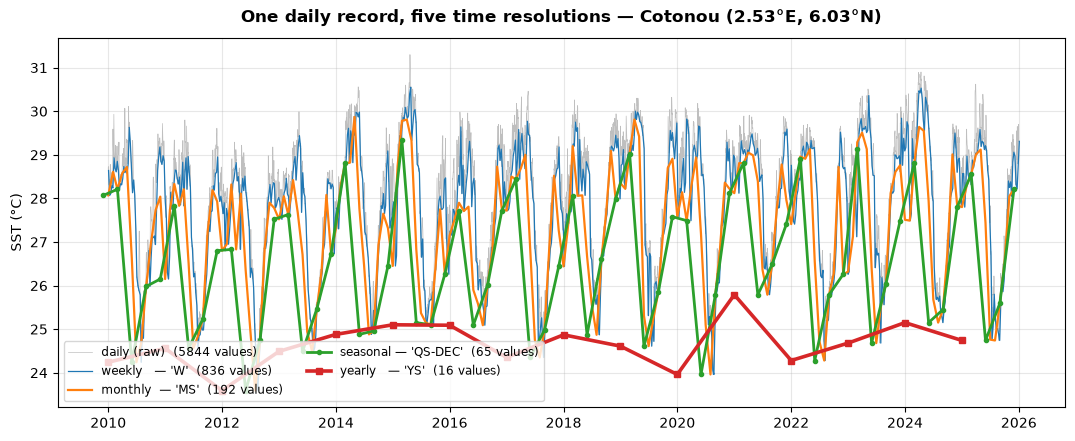

resample(time="MS") -> one value per month of the record : 192
groupby("time.month") -> one value per calendar month      : 12
Warmest calendar month: 5   coldest: 8   seasonal range 4.01 °C


In [23]:
# ============================================================
# STEP 4.5a — RESAMPLE AT ONE POINT: DAILY -> WEEKLY -> MONTHLY
#              -> SEASONAL -> YEARLY  (Everyone runs this)
# ─────────────────────────────────────────────────────────────
# One grid cell from the time-series layout: a few seconds.
# Same code, different frequency code: that is the whole idea.
# ============================================================

DEMO_LON, DEMO_LAT, DEMO_NAME = REF_POINTS[1][0], REF_POINTS[1][1], REF_POINTS[1][2].split('(')[0].strip()

sst_point = (ds_sst_ts['analysed_sst'].sel(longitude=DEMO_LON, latitude=DEMO_LAT, method='nearest') - 273.15).compute()

versions = {
    'daily (raw)'          : sst_point,
    "weekly   — 'W'"       : sst_point.resample(time='W').min(),
    "monthly  — 'MS'"      : sst_point.resample(time='MS').min(),
    "seasonal — 'QS-DEC'"  : sst_point.resample(time='QS-DEC').min(),
    "yearly   — 'YS'"      : sst_point.resample(time='YS').min(),
}

fig, ax = plt.subplots(figsize=(13, 4.8))
styles = [dict(lw=0.5, color='0.75'), dict(lw=0.9), dict(lw=1.6), dict(lw=2.0, marker='o', ms=3), dict(lw=2.6, marker='s', ms=5)]
for (label, da), st in zip(versions.items(), styles):
    ax.plot(da.time, da, label=f'{label}  ({da.sizes["time"]} values)', **st)
ax.set_ylabel('SST (°C)'); ax.grid(alpha=0.3); ax.legend(fontsize=8.5, ncol=2, loc='lower left')
ax.set_title(f'One daily record, five time resolutions — {DEMO_NAME} '
             f'({float(sst_point.longitude):.2f}°E, {float(sst_point.latitude):.2f}°N)')
save_fig(fig, f'Day1_resample_demo_{FILE_PREFIX}.png')
plt.show()

clim = sst_point.groupby('time.month').mean()
print('resample(time="MS") -> one value per month of the record :', versions["monthly  — 'MS'"].sizes['time'])
print('groupby("time.month") -> one value per calendar month      :', clim.sizes['month'])
print(f'Warmest calendar month: {int(clim.idxmax())}   coldest: {int(clim.idxmin())}   '
      f'seasonal range {float(clim.max() - clim.min()):.2f} °C')

In [24]:
ds_sst

<xarray.Dataset> Size: 9GB
Dimensions:       (time: 5844, latitude: 400, longitude: 500)
Coordinates:
  * time          (time) datetime64[ns] 47kB 2010-01-01 ... 2025-12-31
  * latitude      (latitude) float32 2kB -9.975 -9.925 -9.875 ... 9.925 9.975
  * longitude     (longitude) float32 2kB -9.975 -9.925 -9.875 ... 14.93 14.98
Data variables:
    analysed_sst  (time, latitude, longitude) float64 9GB dask.array<chunksize=(100, 400, 500), meta=np.ndarray>
Attributes: (12/48)
    Conventions:                CF-1.4, ACDD-1.3
    Metadata_Conventions:       Unidata Observation Dataset v1.0
    acknowledgment:             Please acknowledge the use of these data with...
    cdm_data_type:              grid
    comment:                    WARNING Some applications are unable to prope...
    creator_email:              servicedesk.cmems@mercator-ocean.eu
    ...                         ...
    time_coverage_end:          19811002T000000Z
    time_coverage_start:        19811001T000000Z
    title:                      Global SST & Sea Ice Analysis, L4 OSTIA, 0.05...
    uuid:                       a2df4a18-6f19-4772-9532-39307a0e2794
    westernmost_longitude:      -180.0
    copernicusmarine_version:   2.5.0

In [ ]:
# TO DO
#2. resample(time='QS-DEC') and groupby('time.season') both talk about seasons. How many values does each return, and why?
#3. Try sst_point.resample(time='MS').count(). What does it tell you about the data?

<div style="border-left:6px solid #E97132; background:#F4F7FC; padding:10px 14px; margin:8px 0; border-radius:4px"><b style="color:#E97132">✍️ Your turn (3 min)</b><br>1. Replace <code>.mean()</code> by <code>.max()</code> in the monthly line: what does the new curve mean?<br>2. <code>resample(time='QS-DEC')</code> and <code>groupby('time.season')</code> both talk about seasons. How many values does each return, and why?<br>3. Try <code>sst_point.resample(time='MS').count()</code>. What does it tell you about the data?</div>

### 4.5b — Build the monthly fields of the whole region, once

Now the same `resample(time='MS').mean()` on **every grid point** of the three daily ocean datasets.
This is the **heavy step of the day**: `xarray` needs every daily field of the period. We compute it **once**, with a progress bar,
and keep the result in memory. **All maps and seasonal figures of Sections 6–7 reuse these monthly fields instantly.**

In [25]:
# ============================================================
# STEP 4.5b — MONTHLY FIELDS FROM DAILY DATA, COMPUTED ONCE
# ─────────────────────────────────────────────────────────────
# SST, sea level, currents : daily -> monthly with resample()
# Wind (ERA5)              : already monthly means
# ============================================================

def to_monthly(da_or_ds):
    # daily -> monthly means, computed once and kept in memory as float32
    return da_or_ds.resample(time='MS').mean().astype('float32').compute()

timings = {}
with ProgressBar():
    t0 = time.time()
    sst_monthly = to_monthly(ds_sst_ts['analysed_sst'] - 273.15)
    sst_monthly.attrs.update(units='°C', long_name='Monthly mean sea surface temperature')
    timings['SST       daily -> monthly'] = time.time() - t0

    t0 = time.time()
    ssh_monthly = to_monthly(ds_ssh)
    timings['Sea level daily -> monthly'] = time.time() - t0

    t0 = time.time()
    curr_monthly = to_monthly(ds_curr)
    timings['Currents  daily -> monthly'] = time.time() - t0

    t0 = time.time()
    wind_monthly = ds_wind.astype('float32').compute()
    timings['Wind      monthly means'] = time.time() - t0

print()
for step, sec in timings.items():
    print(f'   {step:<28} {sec / 60:5.1f} min')
daily_gb = sum(ds.nbytes for ds in [ds_sst_ts, ds_ssh, ds_curr]) / 1e9
mb = sum(da.nbytes for da in [sst_monthly, *ssh_monthly.data_vars.values(),
                                *curr_monthly.data_vars.values(), *wind_monthly.data_vars.values()]) / 1e6
print(f'\n==> {daily_gb:.1f} GB of daily data reduced to {mb:,.0f} MB of monthly fields in memory')
print('    — reused by every map and seasonal figure today')

[########################################] | 100% Completed | 110.62 s
[########################################] | 100% Completed | 115.16 s
[########################################] | 100% Completed | 39.55 s
[########################################] | 100% Completed | 6.29 ss

   SST       daily -> monthly     1.8 min
   Sea level daily -> monthly     1.9 min
   Currents  daily -> monthly     0.7 min
   Wind      monthly means        0.1 min

==> 14.6 GB of daily data reduced to 252 MB of monthly fields in memory
    — reused by every map and seasonal figure today


### 4.6 — Cloud readiness check

<span style="background:#0A2372; color:white; padding:2px 8px; border-radius:4px; font-size:13px">Data block · 14:55–15:00 · gate to Section 5</span>

> Confirm that the data are accessible before Section 5. The check verifies variables, time span and region — not just that something opened.

In [18]:
# ============================================================
# STEP 4.6 — CLOUD READINESS CHECK  (Everyone runs this)
# ─────────────────────────────────────────────────────────────
# Read-only. Checks each dataset covers the variables, period
# and box we asked for.
# ============================================================

CHECKS = [('SST  daily (cloud)',     ds_sst,       ['analysed_sst']),
          ('SSH  daily (cloud)',     ds_ssh,       ['sla', 'adt']),
          ('CURR daily (cloud)',     ds_curr,      ['uo', 've', 'ugos']),
          ('SST  monthly (memory)',  sst_monthly.to_dataset(name='sst'), ['sst']),
          ('SSH  monthly (memory)',  ssh_monthly,  ['sla', 'adt']),
          ('CURR monthly (memory)',  curr_monthly, ['uo', 've', 'ugos']),
          ('WIND monthly',          wind_monthly, ['u10', 'v10'])]

print('=' * 72)
print(f'   OPERA DAY 1 — CLOUD READINESS CHECK   [{DOMAIN_NAME}]')
print('=' * 72)
all_ok = True
tol = np.timedelta64(35, 'D')
for label, ds, needed in CHECKS:
    problems = [f'missing {v}' for v in needed if v not in ds.variables]
    t0, t1 = ds.time.values[0], ds.time.values[-1]
    if t0 - np.datetime64(DATE_START) > tol: problems.append(f'starts {str(t0)[:10]}')
    if np.datetime64(DATE_END) - t1 > tol:   problems.append(f'ends {str(t1)[:10]}')
    la0, la1 = float(ds.latitude.min()), float(ds.latitude.max())
    lo0, lo1 = float(ds.longitude.min()), float(ds.longitude.max())
    if la0 > LAT_MIN + 1 or la1 < LAT_MAX - 1 or lo0 > LON_MIN + 1 or lo1 < LON_MAX - 1:
        problems.append(f'box lon {lo0:.1f}..{lo1:.1f} lat {la0:.1f}..{la1:.1f}')
    status = 'OK     ' if not problems else 'CHECK  '
    all_ok &= not problems
    print(f'  [{status}] {label:<22} {ds.sizes["time"]:>5} steps  {str(t0)[:10]} -> {str(t1)[:10]}')
    for p in problems:
        print(f'             !! {p}')
print('  ' + '-' * 68)
print(f'  Wind source: {WIND_LABEL}')
print()
print('  ==> All datasets ready. Type "ready" in the chat and go to Section 5.' if all_ok
      else '  ==> Something is not right above — show it to your Subgroup Instructor.')
print('=' * 72)

   OPERA DAY 1 — CLOUD READINESS CHECK   [Gulf of Guinea (shared domain)]
  [OK     ] SST  daily (cloud)      5844 steps  2010-01-01 -> 2025-12-31
  [OK     ] SSH  daily (cloud)      5844 steps  2010-01-01 -> 2025-12-31
  [OK     ] CURR daily (cloud)      5844 steps  2010-01-01 -> 2025-12-31
  [OK     ] SST  monthly (memory)    192 steps  2010-01-01 -> 2025-12-01
  [OK     ] SSH  monthly (memory)    192 steps  2010-01-01 -> 2025-12-01
  [OK     ] CURR monthly (memory)    192 steps  2010-01-01 -> 2025-12-01
  [OK     ] WIND monthly             192 steps  2010-01-01 -> 2025-12-01
  --------------------------------------------------------------------
  Wind source: ERA5 monthly means — Earth Data Hub (DestinE)

  ==> All datasets ready. Type "ready" in the chat and go to Section 5.


## Section 5 — Inspecting What Is Inside the Cloud Datasets

<span style="background:#0A2372; color:white; padding:2px 8px; border-radius:4px; font-size:13px">Inspection block · 15:20–16:20 · 60 min</span>

**From this section onwards, everyone runs every cell and nothing new is opened from scratch.**
A streamed dataset behaves exactly like a NetCDF file: same dimensions, coordinates, variables and attributes.

| Concept | Meaning | Quick example |
|---------|---------|--------------|
| **Dataset** | A collection of variables on shared axes | `ds_sst` |
| **DataArray** | One variable with labelled coordinates | `da = ds_sst['analysed_sst']` |
| **Dimensions** | The axes — typically `(time, latitude, longitude)` | `da.dims` |
| **Coordinates** | Actual axis values — dates, lat/lon numbers | `da.time.values` |
| **Attributes** | Metadata: units, long name, source | `da.attrs['units']` |
| **Lazy** | Values not yet transferred (`dask.array`) | `da.data` |

> **MOOC connection:** Modules 5 & 6 introduced gridded ocean data formats. Here we work with them directly.

In [23]:
# ============================================================
# STEP 5.1 — INSPECT THE SST DATASET
# ─────────────────────────────────────────────────────────────
# Look for "dask.array" in the output: the values are still in
# the cloud. Only the description has been read.
# ============================================================

print('=== SST DATASET (daily, still in the cloud) ===')
print(ds_sst)
print()
print('=== VARIABLES ===')
for v, da in ds_sst.data_vars.items():
    print(f'  {v:<25}  dims={da.dims}  shape={da.shape}')
print()
print('=== DIMENSIONS ===')
for dim, size in ds_sst.sizes.items():
    print(f'  {dim:<12} : {size}')
t = ds_sst.time.values
print(f'  Time range    : {str(t[0])[:10]} → {str(t[-1])[:10]}  ({len(t)} steps)')

=== SST DATASET (daily, still in the cloud) ===
<xarray.Dataset> Size: 9GB
Dimensions:       (time: 5844, latitude: 400, longitude: 500)
Coordinates:
  * time          (time) datetime64[ns] 47kB 2010-01-01 ... 2025-12-31
  * latitude      (latitude) float32 2kB -9.975 -9.925 -9.875 ... 9.925 9.975
  * longitude     (longitude) float32 2kB -9.975 -9.925 -9.875 ... 14.93 14.98
Data variables:
    analysed_sst  (time, latitude, longitude) float64 9GB dask.array<chunksize=(100, 400, 500), meta=np.ndarray>
Attributes: (12/48)
    Conventions:                CF-1.4, ACDD-1.3
    Metadata_Conventions:       Unidata Observation Dataset v1.0
    acknowledgment:             Please acknowledge the use of these data with...
    cdm_data_type:              grid
    comment:                    WARNING Some applications are unable to prope...
    creator_email:              servicedesk.cmems@mercator-ocean.eu
    ...                         ...
    time_coverage_end:          19811002T000000Z
    tim

In [24]:
# ============================================================
# STEP 5.2 — INSPECT SST VARIABLE ATTRIBUTES
# ─────────────────────────────────────────────────────────────
# ALWAYS check units before plotting — the most common error
# in ocean data analysis is plotting Kelvin as if it were °C.
# ============================================================

sst_raw = ds_sst['analysed_sst']

print('=== SST ATTRIBUTES ===')
for k, v in sst_raw.attrs.items():
    print(f'  {k:<22} : {v}')
print()
print(' SST is in Kelvin (K) — standard for satellite L4 products.')
print('   Conversion: T(°C) = T(K) − 273.15')
print('   Example: 300 K − 273.15 = 26.85 °C  (typical Gulf of Guinea SST)')

=== SST ATTRIBUTES ===
  comment                :  OSTIA foundation SST
  long_name              : analysed sea surface temperature
  reference              : C.J. Donlon, M. Martin,J.D. Stark, J. Roberts-Jones, E. Fiedler, W. Wimmer. The operational sea surface temperature and sea ice analysis (OSTIA) system. Remote Sensing Environ., 116 (2012), pp. 140-158 http://dx.doi.org/10.1016/j.rse.2010.10.017
  source                 : AMSR2-REMSS-L2P-v2.0, AMSRE-REMSS-L2P-v2.0, TMI-REMSS-L2P-v04, GOES13-OSISAF-L3C-v2.0, SEVIRI-OSISAF-L3C-v2.0, SLSTRA-C3S-L3C-v2.0, ATSR<1,2>-ESACCI-L3U-v2.0, AATSR-ESACCI-L3U-v2.0, AVHRR<06,07,08,09,10,11,12,14,15,16,17,18,19>-ESACCI-L3U-v2.0, AVHRRMTA-ESACCI-L3U-v2.0, GMI-REMSS-L3U-v2.0, VIIRS-OSPO-L3U-v2.0
  standard_name          : sea_surface_foundation_temperature
  units                  : kelvin
  valid_max              : 4500
  valid_min              : -300

 SST is in Kelvin (K) — standard for satellite L4 products.
   Conversion: T(°C) = T(K) − 273.15

In [25]:
# ============================================================
# STEP 5.3 — CONVERT SST TO CELSIUS (only if it is in Kelvin)
# ─────────────────────────────────────────────────────────────
# Step 5.2 showed the units attribute. Here we USE it: convert
# only if the data are really in Kelvin, then verify the result.
# ============================================================

units = str(sst_raw.attrs.get('units', '')).strip().lower()

if units in ('k', 'kelvin'):
    sst_celsius = sst_raw - 273.15
    sst_celsius.attrs = {**sst_raw.attrs, 'units': '°C', 'long_name': 'Sea Surface Temperature (Celsius)'}
    print(f'==> Units are "{units}": converted with T(°C) = T(K) − 273.15')
else:
    sst_celsius = sst_raw
    print(f'==> Units are "{units}": not Kelvin, so no conversion')

# Verify on the first day (only that day is fetched)
sample_c = float(sst_celsius.isel(time=0).mean())
print(f'   Spatial mean of the first day: {sample_c:.2f} °C  ->  '
      + ('✔ plausible for sea water' if -2 < sample_c < 35
         else '⚠ not a sea temperature in °C — check the units before going further'))

==> Units are "kelvin": converted with T(°C) = T(K) − 273.15
   Spatial mean of the first day: 27.37 °C  ->  ✔ plausible for sea water


In [26]:
# ============================================================
# STEP 5.4 — INSPECT SEA LEVEL (daily in the cloud, monthly in memory)
# ============================================================

print('=== SSH DATASET (daily, still in the cloud) ===')
print(ds_ssh)
print()
print(f'=== Built in Step 4.5b: {ssh_monthly.sizes["time"]} monthly fields from {ds_ssh.sizes["time"]} daily fields ===')

sla = ssh_monthly['sla']
print()
print('=== SLA VARIABLE ===')
print(f'  Units     : {sla.attrs.get("units",     "not specified")}')
print(f'  Long name : {sla.attrs.get("long_name", "not specified")}')
print(f'  Shape     : {sla.shape}  (time × lat × lon)')
print()
print('==> SLA = Sea Level Anomaly (metres, relative to a long-term mean sea surface)')
print('   Positive SLA  → sea level above average → warm anti-cyclonic eddy')
print('   Negative SLA  → sea level below average → cold cyclonic eddy or upwelling')
print('   (MOOC Module 6 — interpreting SSH spatial patterns)')

=== SSH DATASET (daily, still in the cloud) ===
<xarray.Dataset> Size: 3GB
Dimensions:    (time: 5844, latitude: 160, longitude: 200)
Coordinates:
  * time       (time) datetime64[ns] 47kB 2010-01-01 2010-01-02 ... 2025-12-31
  * latitude   (latitude) float32 640B -9.938 -9.812 -9.688 ... 9.812 9.938
  * longitude  (longitude) float32 800B -9.938 -9.812 -9.688 ... 14.81 14.94
Data variables:
    sla        (time, latitude, longitude) float64 1GB dask.array<chunksize=(2264, 64, 200), meta=np.ndarray>
    adt        (time, latitude, longitude) float64 1GB dask.array<chunksize=(2264, 64, 200), meta=np.ndarray>
Attributes: (12/43)
    Conventions:                     CF-1.6
    Metadata_Conventions:            Unidata Dataset Discovery v1.0
    cdm_data_type:                   Grid
    comment:                         Sea Surface Height measured by Altimetry...
    contact:                         servicedesk.cmems@mercator-ocean.eu
    creator_email:                   servicedesk.cmems@me

In [27]:
# ============================================================
# STEP 5.5 — INSPECT THE WIND, AND WHAT WAS NORMALISED
# ─────────────────────────────────────────────────────────────
# A second data ecosystem: same xarray tools, different
# conventions. era5_box() made it look like Copernicus Marine.
# ============================================================

print(f'=== WIND — {WIND_LABEL} ===')
print(wind_monthly)
print()
for v in ['u10', 'v10']:
    a = wind_monthly[v].attrs
    print(f'  {v}: {a.get("long_name", a.get("standard_name", ""))} [{a.get("units", "m s-1")}]')
print()
speed = np.hypot(wind_monthly['u10'], wind_monthly['v10'])
print(f'  Mean wind speed over the box: {float(speed.mean()):.2f} m/s')
print(f'  Latitude runs   {float(wind_monthly.latitude[0]):+.2f} -> {float(wind_monthly.latitude[-1]):+.2f}  (south -> north ✔)')
print(f'  Longitude runs  {float(wind_monthly.longitude[0]):+.2f} -> {float(wind_monthly.longitude[-1]):+.2f}  (-180..180 ✔)')

=== WIND — ERA5 monthly means — Earth Data Hub (DestinE) ===
<xarray.Dataset> Size: 13MB
Dimensions:    (time: 192, latitude: 81, longitude: 101)
Coordinates:
  * time       (time) datetime64[ns] 2kB 2010-01-01 2010-02-01 ... 2025-12-01
  * latitude   (latitude) float64 648B -10.0 -9.75 -9.5 -9.25 ... 9.5 9.75 10.0
  * longitude  (longitude) float64 808B -10.0 -9.75 -9.5 ... 14.5 14.75 15.0
Data variables:
    u10        (time, latitude, longitude) float32 6MB -4.873 -4.838 ... -0.1881
    v10        (time, latitude, longitude) float32 6MB 3.357 3.382 ... -2.01
Attributes:
    GRIB_edition:            1
    GRIB_centre:             ecmf
    GRIB_centreDescription:  European Centre for Medium-Range Weather Forecasts
    GRIB_subCentre:          0
    Conventions:             CF-1.7
    institution:             European Centre for Medium-Range Weather Forecasts
    history:                 2026-09-22T20:36 GRIB to CDM+CF via cfgrib-0.9.1...

  u10: 10 metre U wind component [m s**-1]
  v

<div style="border-left:6px solid #E97132; background:#F4F7FC; padding:10px 14px; margin:8px 0; border-radius:4px"><b style="color:#E97132">✍️ Your turn (5 min)</b><br>1. How many GB would the daily SST be if downloaded (Step 4.2)? How many MB do the monthly fields take in memory (Step 4.5b)?<br>2. In <code>ds_sst</code>, what is the grid spacing in degrees? Compute it from <code>ds_sst.latitude</code>.<br>3. Why did we need <code>era5_box()</code> for ERA5 and not for Copernicus Marine?</div>

## Section 6 — First Maps: Your Gallery Walk Outputs

<span style="background:#0A2372; color:white; padding:2px 8px; border-radius:4px; font-size:13px">Independent work block · 16:20–17:20 · 60 min — you work, we circulate</span>

You will produce these maps — every one is saved in `~/OPERA_Workshop/Day1/output/`:

1. **Time-averaged SST** — the climatological temperature pattern
2. **Time-averaged sea level anomaly** — persistent circulation features
3. **SST snapshot — mid-August** — peak of the West African boreal upwelling season
4. **Mean wind over mean SST** — forcing and response together
5–6. **Mean surface currents over SST** — total, Ekman, geostrophic
7–8. **Seasonal Ekman currents and seasonal wind over SST** — the monsoon cycle

==> Saved: ~/OPERA_Workshop/Day1/output/Day1_SST_mean_map_GOG.png


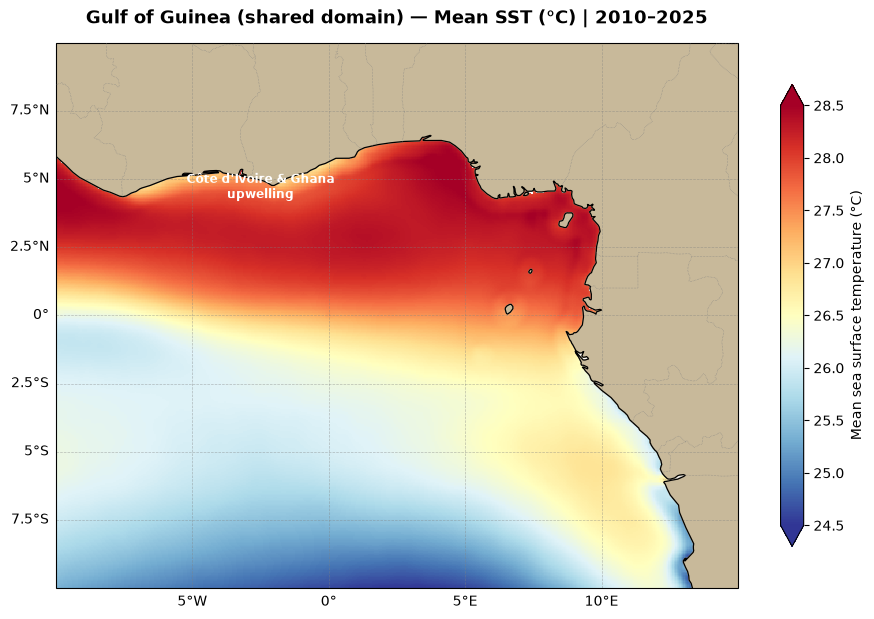

   Regional mean SST: 26.69 °C
###########> Gallery Walk: share this map when your Subgroup Instructor asks.


In [28]:
# ============================================================
# MAP 1: TIME-AVERAGED SST
# ─────────────────────────────────────────────────────────────
# .mean('time') of the monthly fields → climatological SST.
# Reveals persistent features: Guinea Current warmth, the
# Côte d'Ivoire–Ghana upwelling, equatorial patterns.
# Instant: the monthly fields are already in memory.
# ============================================================

sst_mean = sst_monthly.mean('time')
vmin, vmax = robust_range(sst_mean)

fig, ax = plt.subplots(figsize=(11, 7.5), subplot_kw={'projection': PC})
sst_mean.plot(ax=ax, transform=PC, cmap='RdYlBu_r', vmin=vmin, vmax=vmax, extend='both',
              cbar_kwargs={'label': 'Mean sea surface temperature (°C)', 'shrink': 0.8, 'pad': 0.05},
              add_labels=False)
decorate(ax, extent=[LON_MIN, LON_MAX, LAT_MIN, LAT_MAX])
if PHASE == 'shared':
    ax.text(-2.5, 4.3, 'Côte d\'Ivoire & Ghana\nupwelling', fontsize=8.5, color='w',
            ha='center', fontweight='bold', transform=PC, zorder=5)
ax.set_title(f'{DOMAIN_NAME} — Mean SST (°C) | {PERIOD}', fontsize=13)
save_fig(fig, f'Day1_SST_mean_map_{FILE_PREFIX}.png')
plt.show()
print(f'   Regional mean SST: {float(sst_mean.mean()):.2f} °C')
print('###########> Gallery Walk: share this map when your Subgroup Instructor asks.')

==> Saved: ~/OPERA_Workshop/Day1/output/Day1_SSH_mean_map_GOG.png


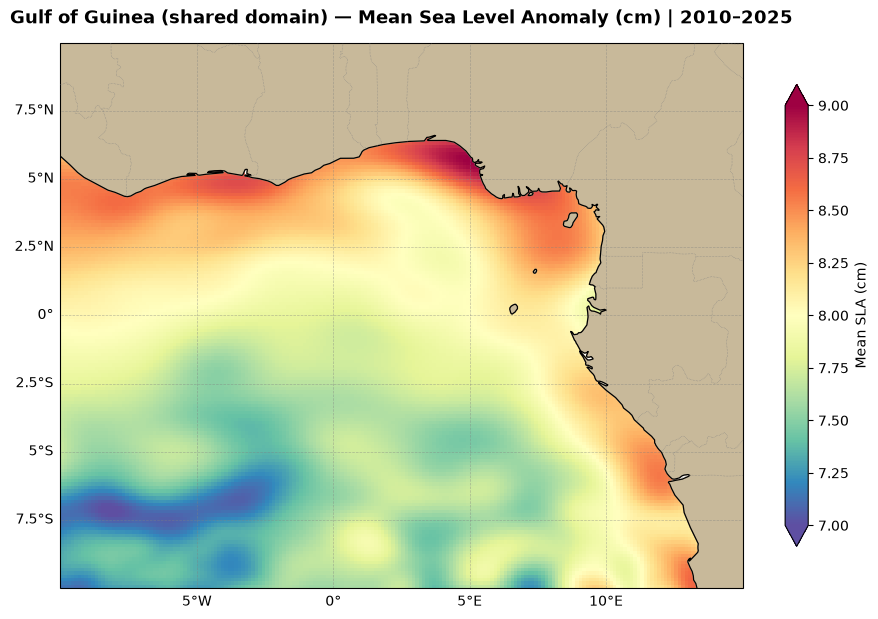

   Domain-mean SLA: 7.9 cm above the 1993–2012 reference


In [29]:
# ============================================================
# MAP 2: TIME-AVERAGED SEA LEVEL ANOMALY
# ─────────────────────────────────────────────────────────────
# SLA is referenced to a 1993–2012 mean, so its time mean over
# 2010–2023 is mostly the sea-level RISE since then, plus
# persistent circulation features. Connect to Module 6.
# ============================================================

sla_mean = 100 * ssh_monthly['sla'].mean('time')
vmin, vmax = robust_range(sla_mean, step=0.5)

fig, ax = plt.subplots(figsize=(11, 7.5), subplot_kw={'projection': PC})
sla_mean.plot(ax=ax, transform=PC, cmap='Spectral_r', vmin=vmin, vmax=vmax, extend='both',
              cbar_kwargs={'label': 'Mean SLA (cm)', 'shrink': 0.8, 'pad': 0.05}, add_labels=False)
decorate(ax, extent=[LON_MIN, LON_MAX, LAT_MIN, LAT_MAX])
ax.set_title(f'{DOMAIN_NAME} — Mean Sea Level Anomaly (cm) | {PERIOD}', fontsize=13)
save_fig(fig, f'Day1_SSH_mean_map_{FILE_PREFIX}.png')
plt.show()
print(f'   Domain-mean SLA: {float(sla_mean.mean()):.1f} cm above the 1993–2012 reference')

==> Saved: ~/OPERA_Workshop/Day1/output/Day1_SST_snapshot_2015-08-15_GOG.png


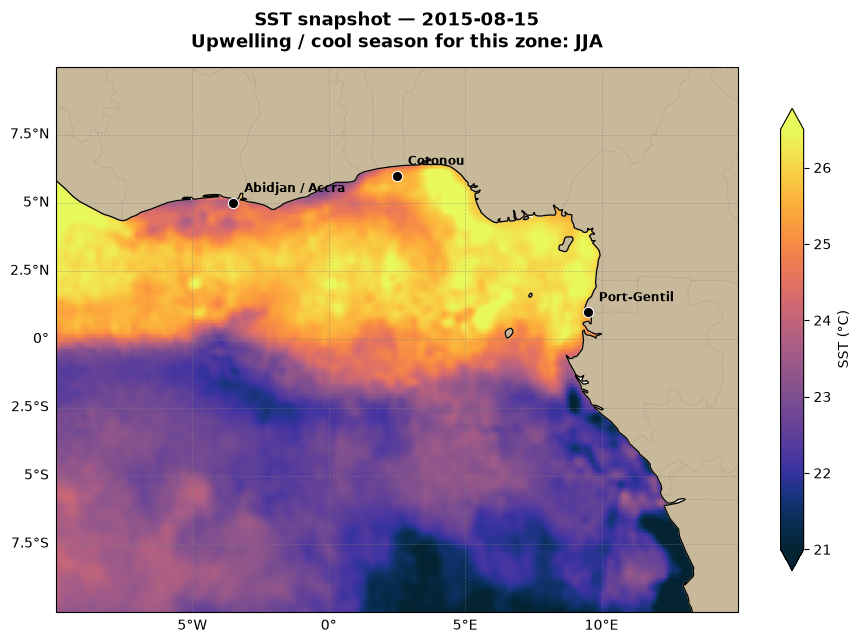

==> Gallery Walk annotation points:
   • Cold patch off Côte d'Ivoire & Ghana → seasonal coastal upwelling
   • Compare with the mean map: how different is this day from the 14-year mean?


In [31]:
# ============================================================
# MAP 3: SST SNAPSHOT — MID-AUGUST
# ─────────────────────────────────────────────────────────────
# Mid-August is the peak of the West African boreal upwelling
# season. One day, from the map-friendly layout: only that day's
# field is transferred.
# ============================================================

sst_snap = (ds_sst['analysed_sst'].sel(time=SNAP_DATE, method='nearest') - 273.15).compute()
actual   = str(sst_snap.time.values)[:10]
SNAP_VMIN, SNAP_VMAX = robust_range(sst_snap, step=0.5)

fig, ax = plt.subplots(figsize=(11, 7.5), subplot_kw={'projection': PC})
sst_snap.plot(ax=ax, transform=PC, cmap=cmocean.cm.thermal, vmin=SNAP_VMIN, vmax=SNAP_VMAX,
              cbar_kwargs={'label': 'SST (°C)', 'shrink': 0.8, 'extend': 'both'}, add_labels=False)
decorate(ax, extent=[LON_MIN, LON_MAX, LAT_MIN, LAT_MAX])
for lon, lat, label in [(p[0], p[1], p[2].split('(')[0].strip()) for p in REF_POINTS]:
    ax.scatter(lon, lat, s=55, color='black', edgecolor='white', lw=0.8, transform=PC, zorder=5)
    ax.text(lon + 0.4, lat + 0.4, label, fontsize=8.5, fontweight='bold', transform=PC, zorder=6)
ax.set_title(f'SST snapshot — {actual}\nUpwelling / cool season for this zone: {Z["upwell_season"]}', fontsize=13)
save_fig(fig, f'Day1_SST_snapshot_{actual}_{FILE_PREFIX}.png')
plt.show()
print('==> Gallery Walk annotation points:')
print('   • Cold patch off Côte d\'Ivoire & Ghana → seasonal coastal upwelling')
print('   • Compare with the mean map: how different is this day from the 14-year mean?')

### Map 4: Wind over SST — forcing and response together

<span style="background:#0A2372; color:white; padding:2px 8px; border-radius:4px; font-size:13px">Independent work block · 16:20–17:20</span>

This is the map that ties the workshop back to the MOOC.

**Colour** is sea surface temperature — the ocean's response.
**Arrows** are the mean wind (ERA5) — the forcing that produced it.

What to look for depends on your zone, and the differences are the point:

| Zone | What the wind is doing |
|------|------------------------|
| **1 — Mauritania / Senegal** | Northeasterly trades blow *along* the coast. Ekman transport carries surface water offshore, cold water rises to replace it. Expect the arrows to run parallel to the shore and the coldest water hard against the coast. |
| **2 — Gulf of Guinea** | South-east trades cross the equator and turn into the south-westerly monsoon over West Africa. Near the equator the Coriolis parameter *f* vanishes, so **both** the Ekman relation (wind → transport at 90°) and geostrophic balance break down **at** the equator. Just off it, *f* changes sign, so the same wind pushes surface water **north** on one side and **south** on the other: the water spreads apart and cold water rises — the **equatorial cold tongue**. A different mechanism from coastal upwelling, with the same result: cold SST. |
| **3 — Agulhas** | Strong westerlies, but the Agulhas is an inertial western boundary current. The wind is not driving it locally. Strong wind, and the SST pattern owes it almost nothing. |

> **The question to bring to the plenary:** same physics, same product, three completely different relationships between wind and SST. Why?

---

==> Saved: ~/OPERA_Workshop/Day1/output/Day1_wind_over_SST_GOG.png


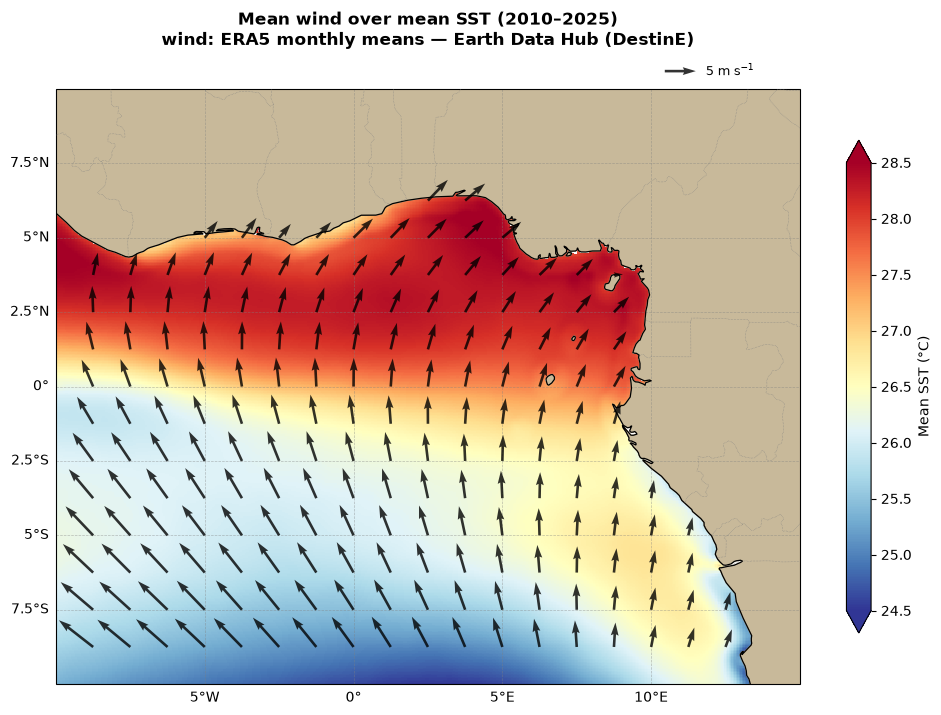

   Mean wind speed over the ocean : 4.73 m/s
   Maximum mean wind speed        : 7.16 m/s

   Compare with your subgroup: is the wind blowing ALONG your coast
   or ONTO it? That single question decides whether you get upwelling.


In [32]:
# ============================================================
# MAP 4: MEAN WIND VECTORS OVER MEAN SST
# ─────────────────────────────────────────────────────────────
# Two datasets, two services, one figure. Wind is 0.25°, SST is
# 0.05°: we thin the arrows rather than interpolate — a quiver
# plot is unreadable with an arrow at every point.
# ============================================================

SHOW_WIND_OVER_LAND = False      # ✍️ True = keep ERA5 arrows over the continent

def ocean_only(da):
    """Hide values over land, using the SST ocean mask (nearest grid point)."""
    ocean = np.isfinite(sst_mean.interp(latitude=da.latitude, longitude=da.longitude, method='nearest'))
    return da.where(ocean)

u_mean = wind_monthly['u10'].mean('time')
v_mean = wind_monthly['v10'].mean('time')
if not SHOW_WIND_OVER_LAND:
    u_mean, v_mean = ocean_only(u_mean), ocean_only(v_mean)
wind_speed = np.hypot(u_mean, v_mean)

vmin, vmax = robust_range(sst_mean)
fig, ax = plt.subplots(figsize=(12, 8), subplot_kw={'projection': PC})
sst_mean.plot(ax=ax, transform=PC, cmap='RdYlBu_r', vmin=vmin, vmax=vmax, extend='both',
              cbar_kwargs={'label': 'Mean SST (°C)', 'shrink': 0.8, 'pad': 0.05}, add_labels=False, zorder=1)
arrows(ax, u_mean, v_mean, n_across=20, scale=120, key=5, key_label='5 m s$^{-1}$', key_xy=(0.86, 1.03))
decorate(ax, extent=[LON_MIN, LON_MAX, LAT_MIN, LAT_MAX])
ax.set_title(f'Mean wind over mean SST ({PERIOD})\nwind: {WIND_LABEL}', fontsize=12, y=1.06)
save_fig(fig, f'Day1_wind_over_SST_{FILE_PREFIX}.png')
plt.show()

print(f'   Mean wind speed over the ocean : {float(wind_speed.mean()):.2f} m/s')
print(f'   Maximum mean wind speed        : {float(wind_speed.max()):.2f} m/s')
print()
print('   Compare with your subgroup: is the wind blowing ALONG your coast')
print('   or ONTO it? That single question decides whether you get upwelling.')

### 🔎 Reading Map 4 — forcing and response together

**The wind (arrows).** South of the equator, the **south-east trades** blow strongly towards the north-west.
They cross the equator and, deflected to the right by the Coriolis force in the Northern Hemisphere, turn into the
**south-westerly monsoon** that blows onto the coasts of Côte d'Ivoire, Ghana, Togo, Benin and Nigeria.

**The ocean's response (colours).**

| Where | What we see | Why |
|---|---|---|
| North of ~1°N, Bights of Benin and Biafra | **Warmest** water (28–28.5 °C) | Weak winds: little mixing, little upwelling |
| South of the equator, especially the south-west of the box | **Coolest** water (24.5–26 °C) | The wind has its strongest **easterly** component here: just off the equator, Ekman transport goes north on one side and south on the other, the surface water spreads apart and cold water rises — **equatorial divergence** |
| East of ~5°E, south of the equator | Cooler, but less than in the west | The wind blows almost due north: a weaker easterly component, so a weaker divergence |
| Along Gabon and Congo | A cooler coastal band | South-easterly winds and coastal currents — a third, separate cooling area |

> **Careful — this is a mean over the whole period.**
> The **equatorial cold tongue** is mainly a **June–September** feature: in an annual mean it appears as a broad cool area,
> not a sharp tongue. **Map 8** (seasonal wind over SST) shows it clearly in JJA.

> **An open question for Day 3.** The **coastal upwelling of Côte d'Ivoire and Ghana** is barely visible here — only a thin,
> slightly cooler strip near 5°N, west of 2°E. It is seasonal, and the local wind blows **onto** the coast rather than along it,
> so local Ekman transport alone cannot explain it. *What else could bring cold water to that coast?*

**✍️ Discuss with your subgroup (3 min):** where is the wind strongest, and where is the water coldest? Do they match everywhere?

==> Saved: ~/OPERA_Workshop/Day1/output/Day1_ekman_divergence_JJA_GOG.png


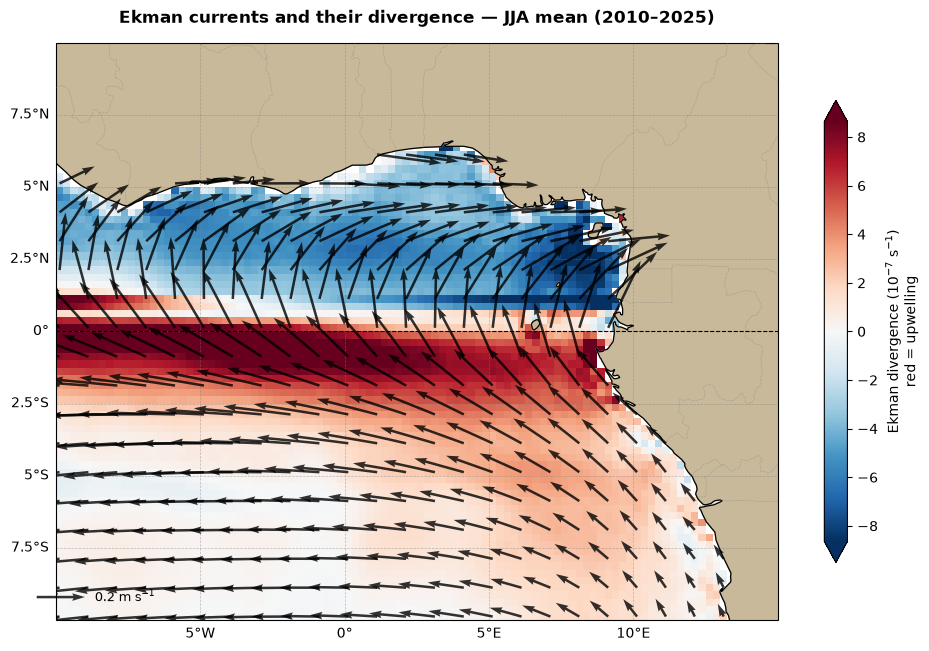

In [35]:
# ============================================================
# SEEING THE EQUATORIAL DIVERGENCE — EKMAN CURRENTS, JUNE–AUGUST
# ─────────────────────────────────────────────────────────────
# Divergence > 0 (red): surface water spreads apart -> water must
# rise from below = UPWELLING. Divergence < 0 (blue): convergence.
# ============================================================

SEASON = 'JJA'                                   # ✍️ try 'DJF' to compare
ek = curr_monthly[['ue', 've']].sel(time=curr_monthly.time.dt.season == SEASON).mean('time')

R = 6.371e6                                      # Earth radius (m)
deg = np.pi / 180
coslat = np.cos(np.deg2rad(ek.latitude))
dudx = ek['ue'].differentiate('longitude') / (R * coslat * deg)
dvdy = ek['ve'].differentiate('latitude') / (R * deg)
divergence = (dudx + dvdy) * 1e7                 # in 10⁻⁷ s⁻¹

fig, ax = plt.subplots(figsize=(12, 7.5), subplot_kw={'projection': PC})
dmax = float(np.nanpercentile(np.abs(divergence), 95))
divergence.plot(ax=ax, transform=PC, cmap='RdBu_r', vmin=-dmax, vmax=dmax,
                cbar_kwargs={'label': 'Ekman divergence (10$^{-7}$ s$^{-1}$)\nred = upwelling', 'shrink': 0.8},
                add_labels=False, zorder=1)
arrows(ax, ek['ue'], ek['ve'], n_across=22, scale=3.0, key=0.2, key_label='0.2 m s$^{-1}$', key_xy=(0.04, 0.04))
ax.axhline(0, color='k', lw=0.8, ls='--', zorder=5)          # the equator
decorate(ax, extent=[LON_MIN, LON_MAX, LAT_MIN, LAT_MAX])
ax.set_title(f'Ekman currents and their divergence — {SEASON} mean ({PERIOD})', fontsize=12)
save_fig(fig, f'Day1_ekman_divergence_{SEASON}_{FILE_PREFIX}.png')
plt.show()

==> Saved: ~/OPERA_Workshop/Day1/output/Day1_ekman_current_over_SST_GOG.png


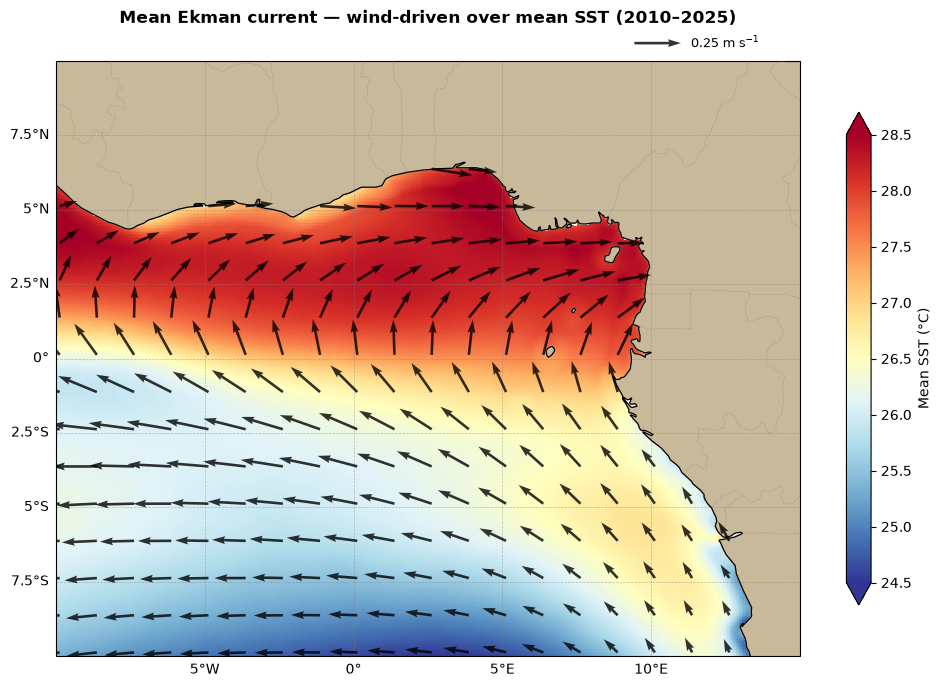

   Mean current speed over domain : 17.5 cm/s
   Maximum mean current speed     : 27.9 cm/s

   Now change COMPONENT above and re-run:
     ekman       -> should resemble your wind map (Map 4)
     geostrophic -> should follow your SLA gradients (Map 2)


In [36]:
# ============================================================
# MAP 5: MEAN SURFACE CURRENTS OVER MEAN SST — ONE COMPONENT
# ─────────────────────────────────────────────────────────────
# The currents dataset holds three decompositions of the flow.
# Switch COMPONENT and re-run (instant — data in memory):
#   'total'       uo / vo       everything combined
#   'ekman'       ue / ve       the part the wind drives directly
#   'geostrophic' ugos / vgos   the part pressure gradients drive
# ============================================================

COMPONENT = 'ekman'          # ✍️ 'total' | 'ekman' | 'geostrophic'

PAIRS = {'total':       ('uo',   'vo',   'Total surface current'),
         'ekman':       ('ue',   've',   'Ekman current — wind-driven'),
         'geostrophic': ('ugos', 'vgos', 'Geostrophic current — pressure-driven')}
un, vn, label = PAIRS[COMPONENT]

u_c = curr_monthly[un].mean('time')
v_c = curr_monthly[vn].mean('time')
cur_speed = np.hypot(u_c, v_c)

fig, ax = plt.subplots(figsize=(12, 8), subplot_kw={'projection': PC})
sst_mean.plot(ax=ax, transform=PC, cmap='RdYlBu_r', vmin=vmin, vmax=vmax, extend='both',
              cbar_kwargs={'label': 'Mean SST (°C)', 'shrink': 0.8, 'pad': 0.05}, add_labels=False, zorder=1)
arrows(ax, u_c, v_c, n_across=20, scale=4.0, key=0.25, key_label='0.25 m s$^{-1}$', key_xy=(0.84, 1.03))
decorate(ax, extent=[LON_MIN, LON_MAX, LAT_MIN, LAT_MAX])
ax.set_title(f'Mean {label} over mean SST ({PERIOD})', fontsize=12, y=1.05)
save_fig(fig, f'Day1_{COMPONENT}_current_over_SST_{FILE_PREFIX}.png')
plt.show()

print(f'   Mean current speed over domain : {float(cur_speed.mean()) * 100:.1f} cm/s')
print(f'   Maximum mean current speed     : {float(cur_speed.max()) * 100:.1f} cm/s')
print()
print('   Now change COMPONENT above and re-run:')
print('     ekman       -> should resemble your wind map (Map 4)')
print('     geostrophic -> should follow your SLA gradients (Map 2)')

==> Saved: ~/OPERA_Workshop/Day1/output/Day1_currents_over_SST_GOG.png


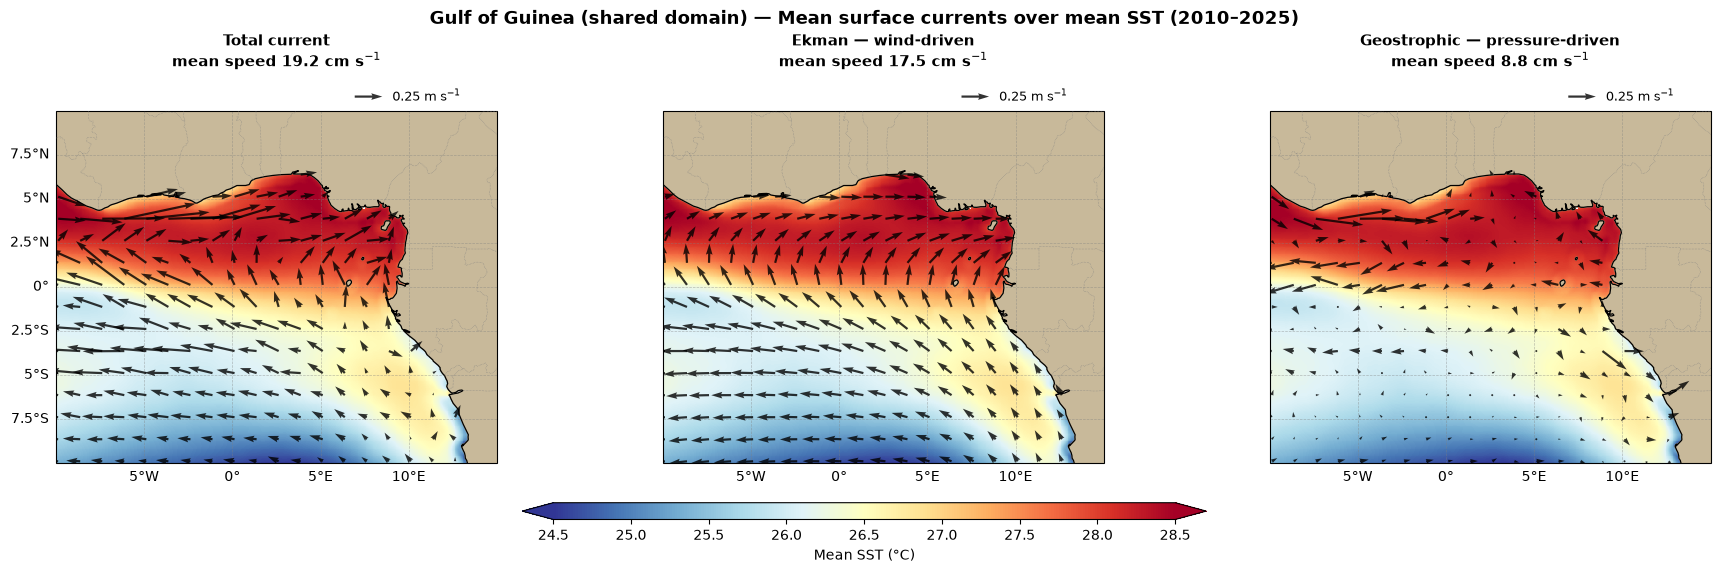

   What to look for:
   • Total ≈ Ekman + geostrophic. Which one dominates where?
   • Ekman should follow the wind map you just made — check it.
   • Geostrophic should follow the SLA gradients — check that too.
   • Near the equator geostrophic balance no longer holds (f → 0).


In [37]:
# ============================================================
# MAP 6: SURFACE CURRENTS OVER SST — TOTAL, EKMAN, GEOSTROPHIC
# ─────────────────────────────────────────────────────────────
# Side by side, the three panels answer a question you cannot
# ask of the total alone: WHICH part of this flow does the wind
# drive?
# ============================================================

COMPONENTS = [('uo',   'vo',   'Total current'),
              ('ue',   've',   'Ekman — wind-driven'),
              ('ugos', 'vgos', 'Geostrophic — pressure-driven')]

fig, axes = plt.subplots(1, 3, figsize=(19, 5.6), subplot_kw={'projection': PC})
fig.subplots_adjust(left=0.04, right=0.98, top=0.80, bottom=0.17, wspace=0.06)
for ax, (un, vn, label) in zip(axes, COMPONENTS):
    u, v = curr_monthly[un].mean('time'), curr_monthly[vn].mean('time')
    im = sst_mean.plot(ax=ax, transform=PC, cmap='RdYlBu_r', vmin=vmin, vmax=vmax,
                       add_colorbar=False, add_labels=False, zorder=1)
    arrows(ax, u, v, n_across=18, scale=4.0, key=0.25, key_label='0.25 m s$^{-1}$',
           key_xy=(0.74, 1.04), width=0.005)
    decorate(ax, extent=[LON_MIN, LON_MAX, LAT_MIN, LAT_MAX], left=(ax is axes[0]))
    ax.set_title(f'{label}\nmean speed {float(np.hypot(u, v).mean()) * 100:.1f} cm s$^{{-1}}$', fontsize=11, y=1.10)

cax = fig.add_axes([0.32, 0.07, 0.36, 0.03])
fig.colorbar(im, cax=cax, orientation='horizontal', extend='both', label='Mean SST (°C)')
fig.suptitle(f'{DOMAIN_NAME} — Mean surface currents over mean SST ({PERIOD})', fontsize=13, fontweight='bold', y=0.98)
save_fig(fig, f'Day1_currents_over_SST_{FILE_PREFIX}.png')
plt.show()

print('   What to look for:')
print('   • Total ≈ Ekman + geostrophic. Which one dominates where?')
print('   • Ekman should follow the wind map you just made — check it.')
print('   • Geostrophic should follow the SLA gradients — check that too.')
print('   • Near the equator geostrophic balance no longer holds (f → 0).')

==> Saved: ~/OPERA_Workshop/Day1/output/Day1_seasonal_ekman_GOG.png


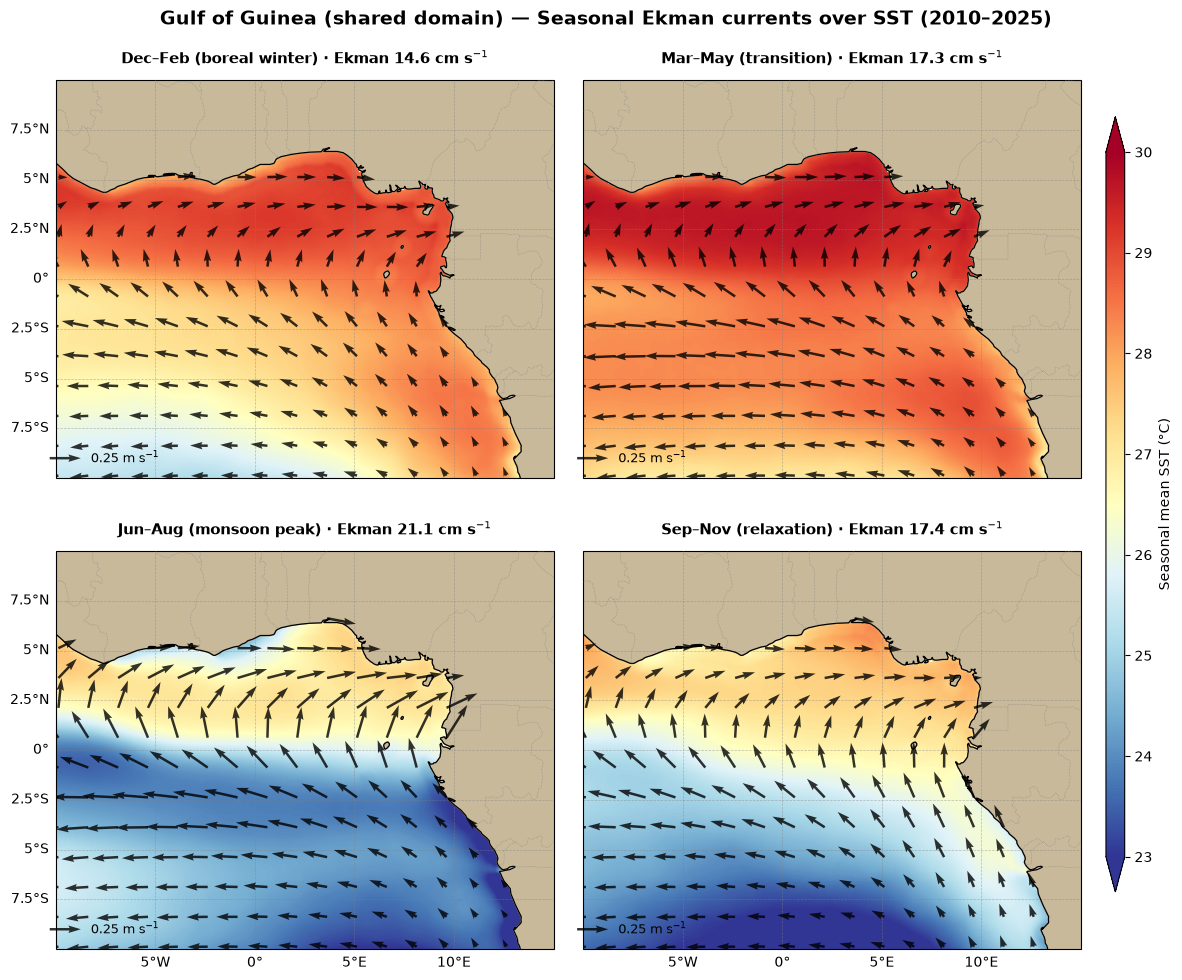

   Seasonal cycle of the Ekman response:
     DJF    14.6 cm/s  #######
     MAM    17.3 cm/s  ########
     JJA    21.1 cm/s  ##########
     SON    17.4 cm/s  ########

   • Compare DJF and JJA. How much does the Ekman flow change?
   • Southern-hemisphere zones: JJA is your WINTER, not summer.


In [41]:
# ============================================================
# MAP 7: SEASONAL EKMAN CURRENTS — THE MONSOON CYCLE
# ─────────────────────────────────────────────────────────────
# Means hide seasons. The Ekman component is wind-driven, so it
# should swing with the monsoon: the ITCZ migrates north in boreal
# summer, the southerly winds strengthen and the equatorial cold
# tongue develops. Watch JJA in particular.
# ============================================================

SEASONS = [('DJF', 'Dec–Feb (boreal winter)'),
           ('MAM', 'Mar–May (transition)'),
           ('JJA', 'Jun–Aug (monsoon peak)'),
           ('SON', 'Sep–Nov (relaxation)')]

sst_season  = sst_monthly.groupby('time.season').mean('time')
curr_season = curr_monthly.groupby('time.season').mean('time')

SNAP_VMIN, SNAP_VMAX = 23, 30

fig, axes = plt.subplots(2, 2, figsize=(12.5, 10.2), subplot_kw={'projection': PC})
fig.subplots_adjust(left=0.06, right=0.88, top=0.90, bottom=0.04, wspace=0.06, hspace=0.16)

ekman_speed = {}
for ax, (code_, title) in zip(axes.flat, SEASONS):
    u, v = curr_season['ue'].sel(season=code_), curr_season['ve'].sel(season=code_)
    ekman_speed[code_] = float(np.hypot(u, v).mean())
    im = sst_season.sel(season=code_).plot(ax=ax, transform=PC, cmap='RdYlBu_r', vmin=SNAP_VMIN, vmax=SNAP_VMAX,
                                           extend='both', add_colorbar=False, add_labels=False, zorder=1)
    arrows(ax, u, v, n_across=16, scale=4.0, key=0.25, key_label='0.25 m s$^{-1}$',
           key_xy=(0.05, 0.05), width=0.005)                       # reference arrow inside the map
    decorate(ax, extent=[LON_MIN, LON_MAX, LAT_MIN, LAT_MAX],
             left=(ax in axes[:, 0]), bottom=(ax in axes[1, :]))   # labels only on the outer edges
    ax.set_title(f'{title} · Ekman {ekman_speed[code_] * 100:.1f} cm s$^{{-1}}$', fontsize=10.5)

fig.colorbar(im, cax=fig.add_axes([0.90, 0.10, 0.015, 0.76]), extend='both', label='Seasonal mean SST (°C)')
fig.suptitle(f'{DOMAIN_NAME} — Seasonal Ekman currents over SST ({PERIOD})', fontsize=14, fontweight='bold', y=0.965)
save_fig(fig, f'Day1_seasonal_ekman_{FILE_PREFIX}.png')
plt.show()

print('   Seasonal cycle of the Ekman response:')
for code_, spd in ekman_speed.items():
    print(f'     {code_}   {spd * 100:>5.1f} cm/s  {"#" * int(spd * 100 / 2)}')
print()
print('   • Compare DJF and JJA. How much does the Ekman flow change?')
print('   • Southern-hemisphere zones: JJA is your WINTER, not summer.')

==> Saved: ~/OPERA_Workshop/Day1/output/Day1_seasonal_wind_GOG.png


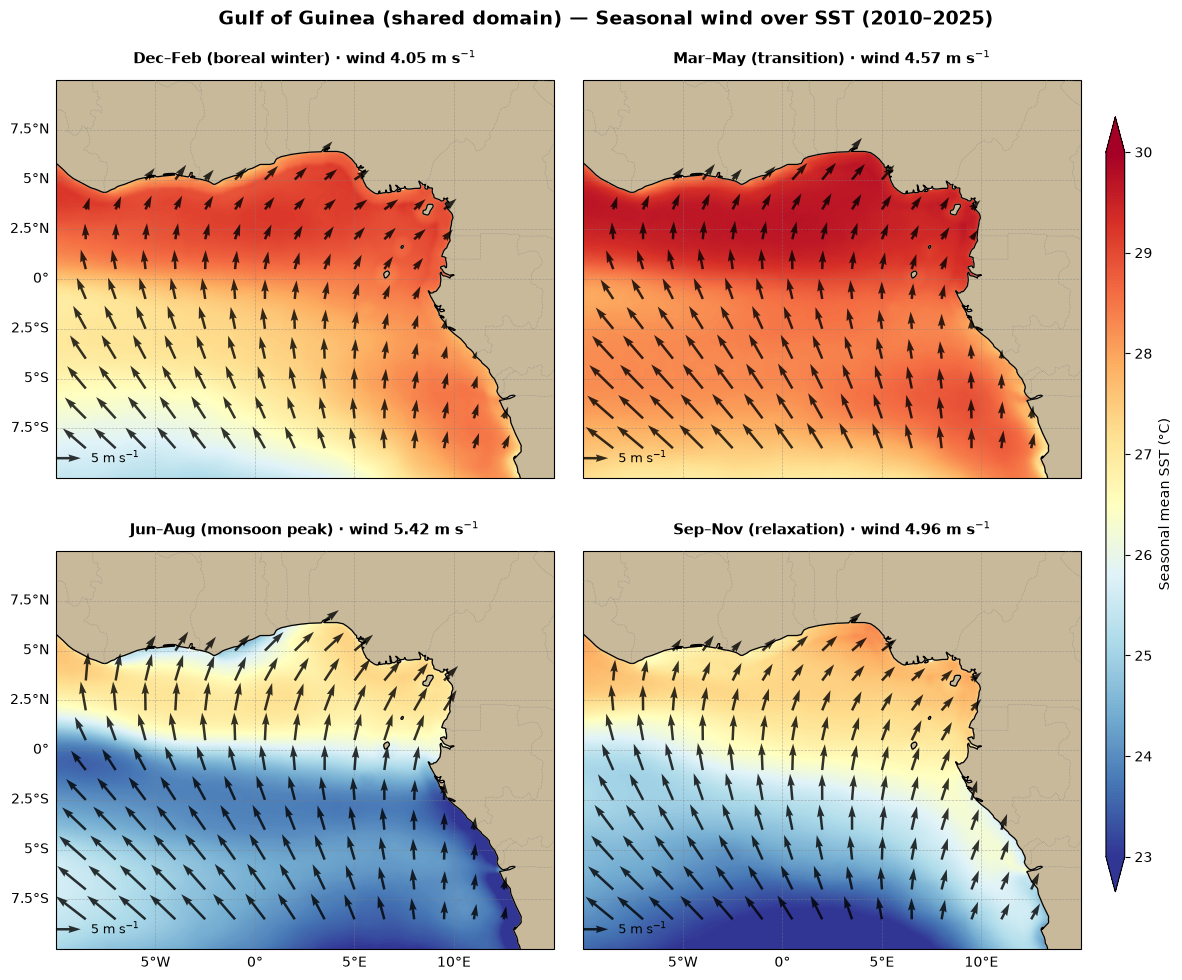

   FORCING AND RESPONSE — compare with Map 7:
     DJF   wind  4.05 m/s    Ekman  14.6 cm/s
     MAM   wind  4.57 m/s    Ekman  17.3 cm/s
     JJA   wind  5.42 m/s    Ekman  21.1 cm/s
     SON   wind  4.96 m/s    Ekman  17.4 cm/s

   • Does the wind peak in the same season as the Ekman current?
   • Watch the arrows cross the equator and turn — that is the monsoon.


In [42]:
# ============================================================
# MAP 8: SEASONAL WIND OVER SST — THE FORCING ITSELF
# ─────────────────────────────────────────────────────────────
# Map 7 showed the OCEAN's seasonal response. This shows the
# ATMOSPHERIC FORCING that produced it. If the wind peaks in the
# same season as the Ekman current, you have measured a cause and
# its effect with two products from two different services.
#
# The ITCZ migrates north in boreal summer. South-east trades cross
# the equator, are deflected by Coriolis, and arrive over West
# Africa as south-westerlies carrying the rains.
# ============================================================

wind_season = wind_monthly.groupby('time.season').mean('time')

fig, axes = plt.subplots(2, 2, figsize=(12.5, 10.2), subplot_kw={'projection': PC})
fig.subplots_adjust(left=0.06, right=0.88, top=0.90, bottom=0.04, wspace=0.06, hspace=0.16)

wind_speed_season = {}
for ax, (code_, title) in zip(axes.flat, SEASONS):
    u, v = wind_season['u10'].sel(season=code_), wind_season['v10'].sel(season=code_)
    if not SHOW_WIND_OVER_LAND:
        u, v = ocean_only(u), ocean_only(v)
    wind_speed_season[code_] = float(np.hypot(u, v).mean())
    im = sst_season.sel(season=code_).plot(ax=ax, transform=PC, cmap='RdYlBu_r', vmin=SNAP_VMIN, vmax=SNAP_VMAX,
                                           extend='both', add_colorbar=False, add_labels=False, zorder=1)
    arrows(ax, u, v, n_across=16, scale=100, key=5, key_label='5 m s$^{-1}$',
           key_xy=(0.05, 0.05), width=0.005)                       # reference arrow inside the map
    decorate(ax, extent=[LON_MIN, LON_MAX, LAT_MIN, LAT_MAX],
             left=(ax in axes[:, 0]), bottom=(ax in axes[1, :]))   # labels only on the outer edges
    ax.set_title(f'{title} · wind {wind_speed_season[code_]:.2f} m s$^{{-1}}$', fontsize=10.5)

fig.colorbar(im, cax=fig.add_axes([0.90, 0.10, 0.015, 0.76]), extend='both', label='Seasonal mean SST (°C)')
fig.suptitle(f'{DOMAIN_NAME} — Seasonal wind over SST ({PERIOD})', fontsize=14, fontweight='bold', y=0.965)
save_fig(fig, f'Day1_seasonal_wind_{FILE_PREFIX}.png')
plt.show()

print('   FORCING AND RESPONSE — compare with Map 7:')
for code_ in wind_speed_season:
    print(f'     {code_}   wind {wind_speed_season[code_]:>5.2f} m/s    Ekman {ekman_speed[code_] * 100:>5.1f} cm/s')
print()
print('   • Does the wind peak in the same season as the Ekman current?')
print('   • Watch the arrows cross the equator and turn — that is the monsoon.')

## Section 7 — Time Series: Seasonal Cycles and Interannual Variability

<span style="background:#0A2372; color:white; padding:2px 8px; border-radius:4px; font-size:13px">Independent work block · 16:20–17:20</span>

Maps reveal spatial structure. Time series reveal **temporal dynamics** — the seasonal signal, year-to-year anomalies,
and long-term trends that matter for professional applications.

We extract the **daily SST at the three reference points** from the **time-series layout**: only the few small blocks
containing those points are transferred — a 14-year series in seconds.

> **MOOC connection:** Module 2 — seasonal ocean variability and physical drivers. Module 6 — interpreting variability.
> **Day 2 preview:** tomorrow we quantify anomalies precisely.

In [43]:
# ============================================================
# STEP 7.0 — DAILY SST AT THE THREE REFERENCE POINTS (once)
# ─────────────────────────────────────────────────────────────
# Vectorised selection: the three points in one request.
# method='nearest' picks the closest ocean grid cell.
# ============================================================

lons = xr.DataArray([p[0] for p in REF_POINTS], dims='point')
lats = xr.DataArray([p[1] for p in REF_POINTS], dims='point')

t0 = time.time()
with ProgressBar():
    pts = (ds_sst_ts['analysed_sst'].sel(longitude=lons, latitude=lats, method='nearest') - 273.15).compute()

point_sst = pd.DataFrame({p[2].split('(')[0].strip(): pts.isel(point=i).to_series()
                          for i, p in enumerate(REF_POINTS)})
grid = [(float(pts.longitude[i]), float(pts.latitude[i])) for i in range(len(REF_POINTS))]
print(f'==> {len(point_sst)} days x {point_sst.shape[1]} points in {time.time() - t0:.0f} s')
for name, (glon, glat) in zip(point_sst.columns, grid):
    flag = '' if point_sst[name].notna().any() else '   !! all NaN: the point is on land — nudge it offshore'
    print(f'   {name:<18} grid cell {glon:.2f}°E, {glat:.2f}°N{flag}')

[########################################] | 100% Completed | 27.60 s
==> 5844 days x 3 points in 28 s
   Abidjan / Accra    grid cell -3.47°E, 5.03°N
   Cotonou            grid cell 2.53°E, 6.03°N
   Port-Gentil        grid cell 9.52°E, 1.02°N


   Abidjan / Accra: 2010–2017 27.23 °C -> 2018–2025 27.55 °C  (+0.32)
   Cotonou: 2010–2017 27.91 °C -> 2018–2025 28.27 °C  (+0.37)
   Port-Gentil: 2010–2017 27.69 °C -> 2018–2025 28.02 °C  (+0.33)
==> Saved: ~/OPERA_Workshop/Day1/output/Day1_SST_timeseries_GOG.png


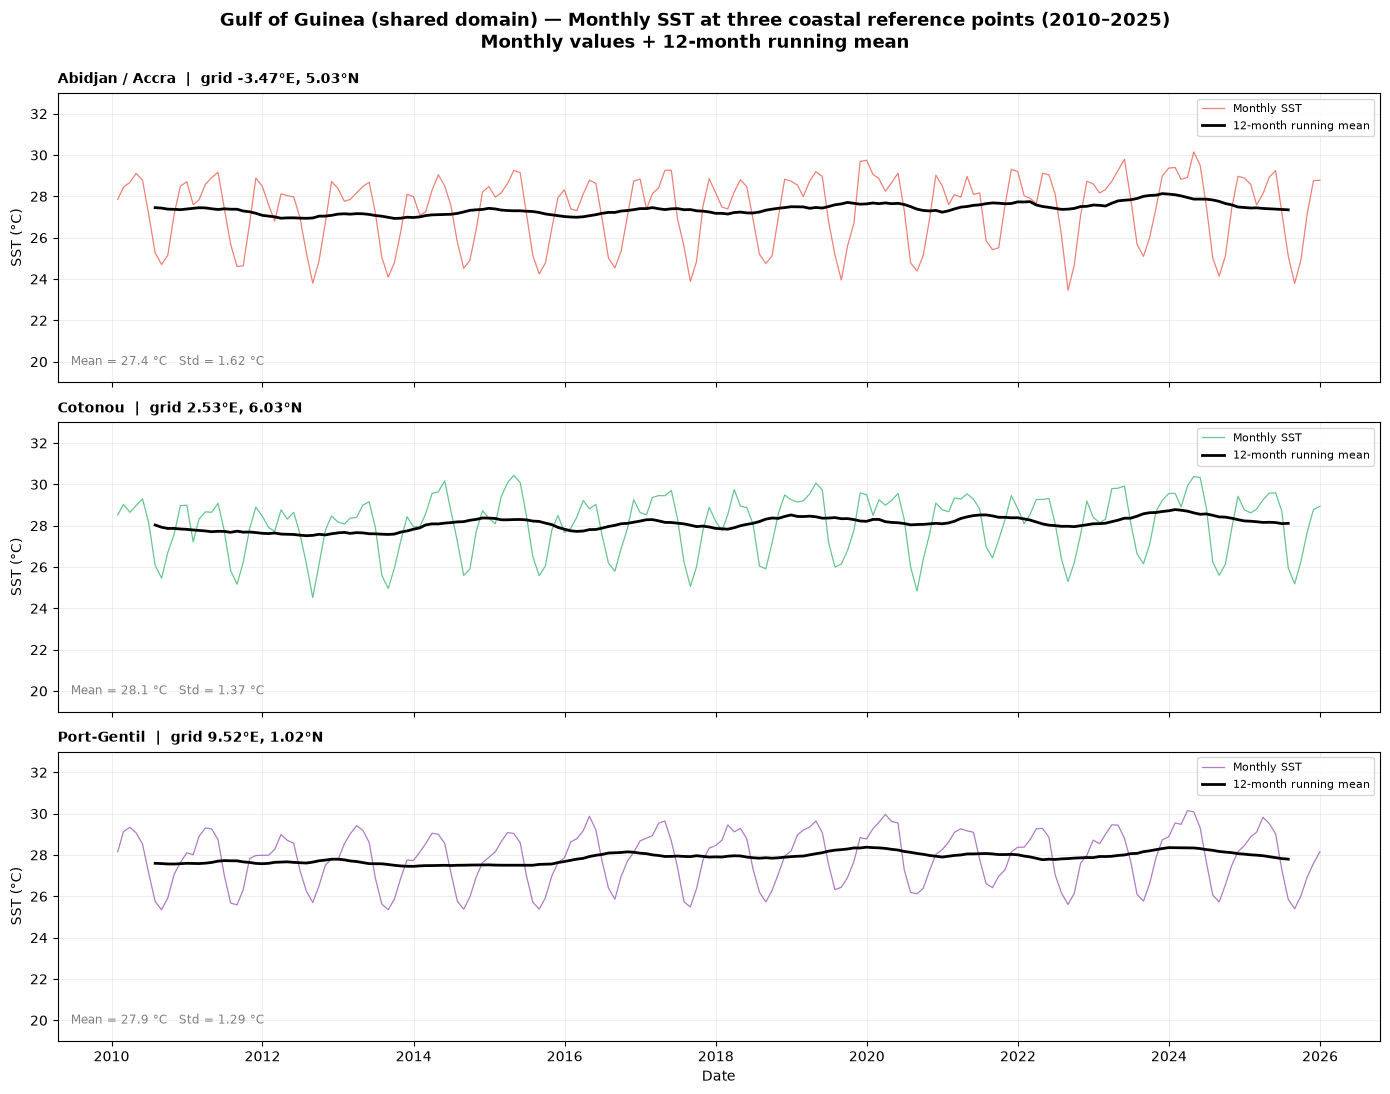

In [44]:
# ============================================================
# TIME SERIES: MONTHLY SST AT THREE COASTAL REFERENCE POINTS
# ─────────────────────────────────────────────────────────────
# Monthly values + 12-month running mean. The first and second
# halves of the record are compared for a warming signal.
# ============================================================

fig, axes = plt.subplots(3, 1, figsize=(14, 11), sharex=True)
fig.suptitle(f'{ZONE_NAME if PHASE == "zone" else DOMAIN_NAME} — Monthly SST at three coastal reference points ({PERIOD})\n'
             'Monthly values + 12-month running mean', fontsize=13, fontweight='bold', y=0.99)

for ax, name, (glon, glat), color in zip(axes, point_sst.columns, grid, COLORS):
    ts_m = point_sst[name].resample('ME').mean()
    rmean = ts_m.rolling(12, center=True).mean()
    half = len(ts_m) // 2
    early, late = ts_m.iloc[:half], ts_m.iloc[half:]
    print(f'   {name}: {early.index[0].year}–{early.index[-1].year} {early.mean():.2f} °C -> '
          f'{late.index[0].year}–{late.index[-1].year} {late.mean():.2f} °C  ({late.mean() - early.mean():+.2f})')

    ax.plot(ts_m.index, ts_m.values, color=color, lw=0.9, alpha=0.7, label='Monthly SST')
    ax.plot(ts_m.index, rmean, color='black', lw=2.0, label='12-month running mean')
    ax.set_ylabel('SST (°C)')
    ax.set_title(f'{name}  |  grid {glon:.2f}°E, {glat:.2f}°N', fontsize=10, loc='left', pad=3)
    ax.legend(fontsize=8, loc='upper right'); ax.grid(True, alpha=0.3, lw=0.5)
    ax.set_ylim(TS_YMIN, TS_YMAX)
    ax.text(0.01, 0.06, f'Mean = {ts_m.mean():.1f} °C   Std = {ts_m.std():.2f} °C',
            transform=ax.transAxes, fontsize=8.5, color='gray')

axes[-1].set_xlabel('Date')
plt.tight_layout()
save_fig(fig, f'Day1_SST_timeseries_{FILE_PREFIX}.png')
plt.show()

==> Saved: ~/OPERA_Workshop/Day1/output/Day1_SST_seasonality_GOG.png


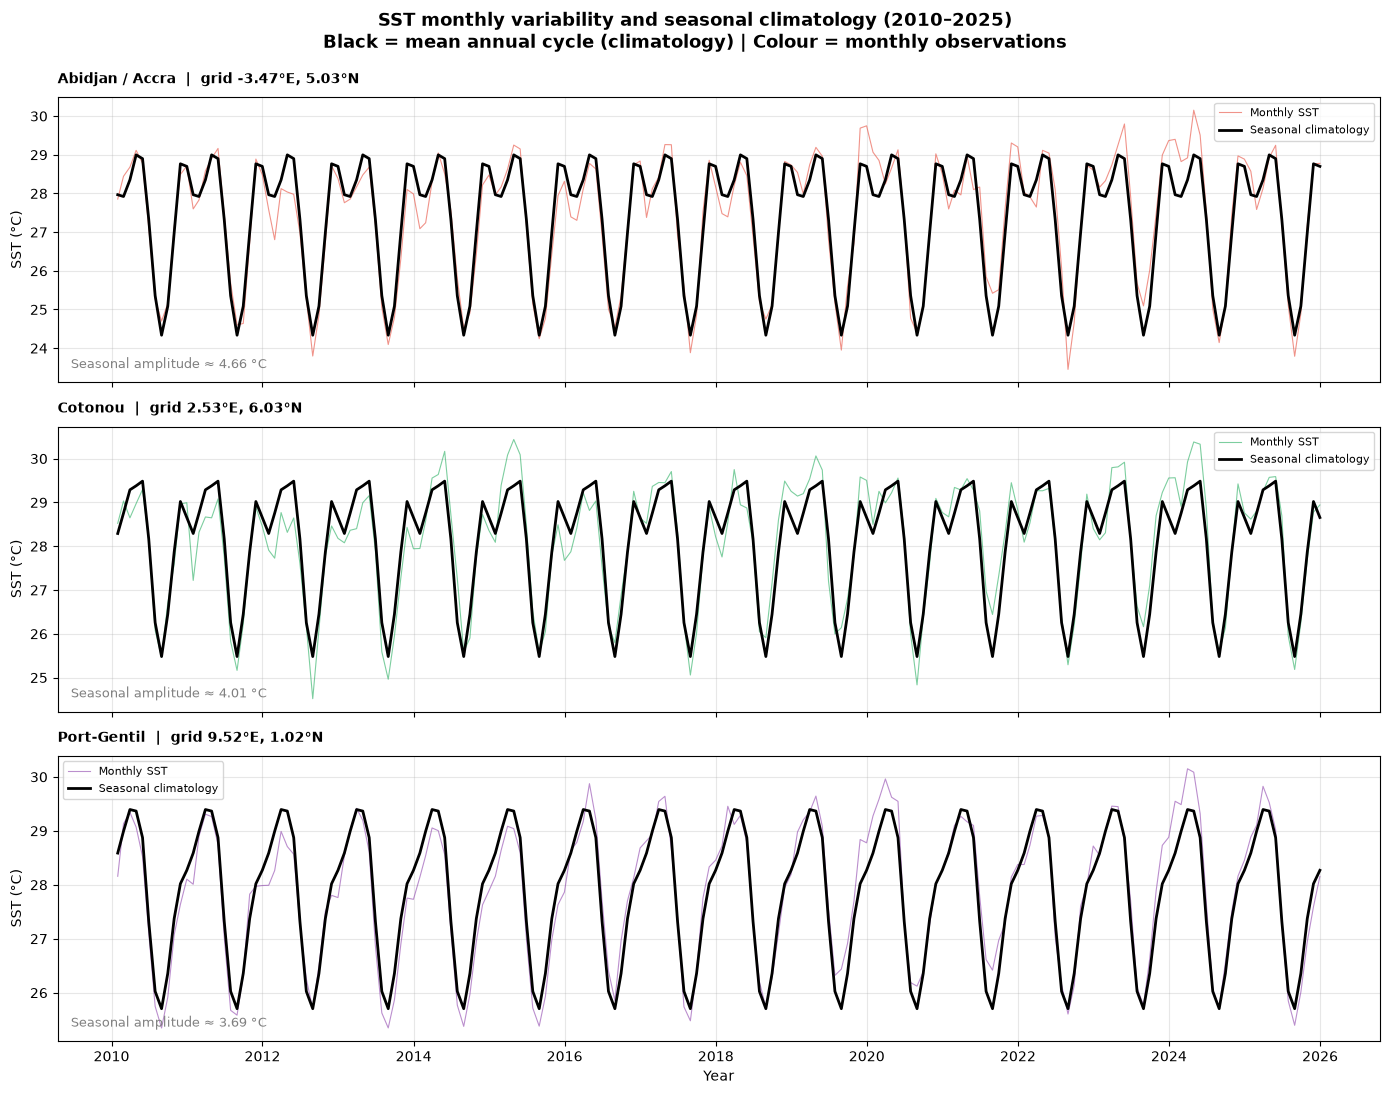

==> Day 2 preview: anomaly = monthly SST − climatology (black line)


In [45]:
# ============================================================
# SEASONAL CLIMATOLOGY — MEAN ANNUAL CYCLE
# ─────────────────────────────────────────────────────────────
# Climatology = mean SST for each calendar month, over all years.
# Coloured line = monthly observations. Deviation from the black
# line = anomaly (Day 2).
# ============================================================

fig, axes = plt.subplots(3, 1, figsize=(14, 11), sharex=True)
fig.suptitle(f'SST monthly variability and seasonal climatology ({PERIOD})\n'
             'Black = mean annual cycle (climatology) | Colour = monthly observations',
             fontsize=13, fontweight='bold', y=0.99)

for ax, name, (glon, glat), color in zip(axes, point_sst.columns, grid, COLORS):
    ts_m = point_sst[name].resample('ME').mean()
    clim = ts_m.groupby(ts_m.index.month).mean()
    ax.plot(ts_m.index, ts_m.values, color=color, lw=0.8, alpha=0.6, label='Monthly SST')
    ax.plot(ts_m.index, ts_m.index.month.map(clim), color='black', lw=2.0, label='Seasonal climatology')
    ax.set_ylabel('SST (°C)')
    ax.set_title(f'{name}  |  grid {glon:.2f}°E, {glat:.2f}°N', fontsize=10, loc='left')
    ax.grid(True, alpha=0.3); ax.legend(fontsize=8)
    ax.text(0.01, 0.05, f'Seasonal amplitude ≈ {clim.max() - clim.min():.2f} °C',
            transform=ax.transAxes, fontsize=9, color='gray')

axes[-1].set_xlabel('Year')
plt.tight_layout()
save_fig(fig, f'Day1_SST_seasonality_{FILE_PREFIX}.png')
plt.show()
print('==> Day 2 preview: anomaly = monthly SST − climatology (black line)')

==> Saved: ~/OPERA_Workshop/Day1/output/Day1_SST_annual_cycle_GOG.png


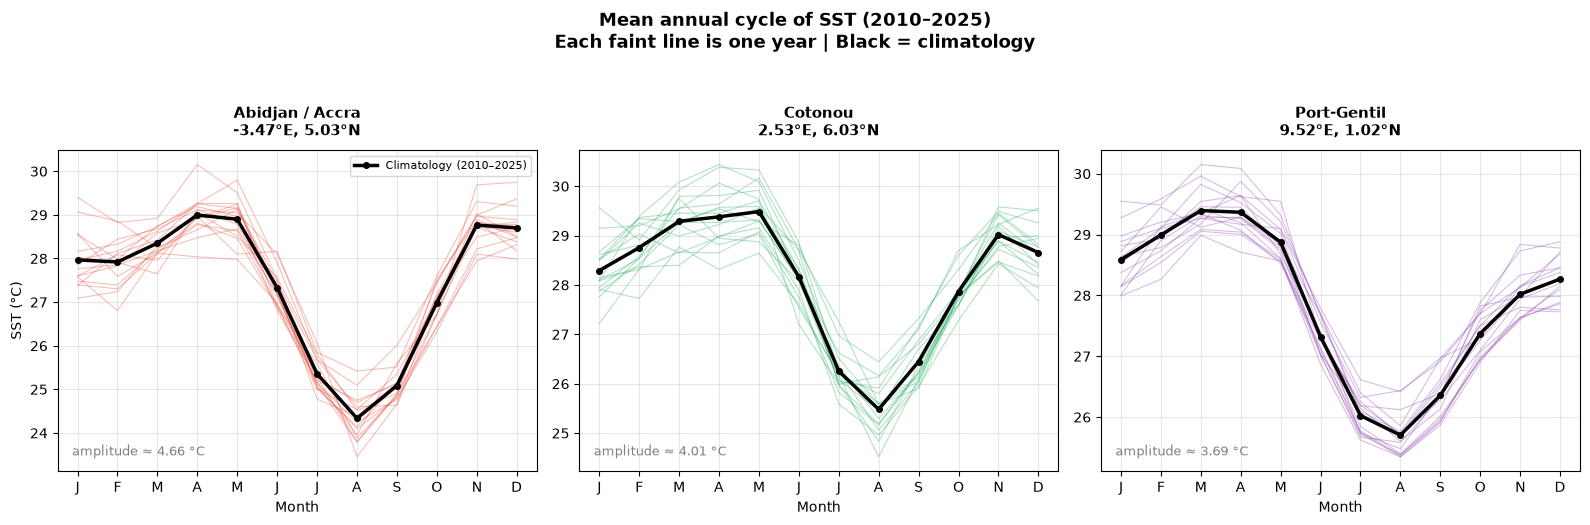

   The SPREAD between faint lines at a given month is the interannual variability.
   Where is it widest — and why?


In [46]:
# ============================================================
# MEAN ANNUAL CYCLE — ONE LINE PER YEAR
# ─────────────────────────────────────────────────────────────
# Each faint line is ONE year folded onto a 12-month axis; the
# bold line is their average. The SPREAD between faint lines is
# the interannual variability — the thing Day 2 measures.
# ============================================================

MONTHS = ['J', 'F', 'M', 'A', 'M', 'J', 'J', 'A', 'S', 'O', 'N', 'D']
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
fig.suptitle(f'Mean annual cycle of SST ({PERIOD})\nEach faint line is one year | Black = climatology',
             fontsize=13, fontweight='bold', y=1.04)

for ax, name, (glon, glat), color in zip(axes, point_sst.columns, grid, COLORS):
    ts_m = point_sst[name].resample('ME').mean()
    clim = ts_m.groupby(ts_m.index.month).mean()
    for yr, grp in ts_m.groupby(ts_m.index.year):
        ax.plot(grp.index.month, grp.values, color=color, lw=0.8, alpha=0.35)
    ax.plot(range(1, 13), clim.values, color='black', lw=2.5, marker='o', markersize=4,
            label=f'Climatology ({PERIOD})', zorder=5)
    ax.set_xticks(range(1, 13)); ax.set_xticklabels(MONTHS); ax.set_xlim(0.5, 12.5)
    ax.set_xlabel('Month')
    ax.set_title(f'{name}\n{glon:.2f}°E, {glat:.2f}°N', fontsize=10.5)
    ax.grid(True, alpha=0.3)
    ax.text(0.03, 0.05, f'amplitude ≈ {clim.max() - clim.min():.2f} °C', transform=ax.transAxes, fontsize=9, color='gray')

axes[0].set_ylabel('SST (°C)'); axes[0].legend(fontsize=8, loc='upper right')
plt.tight_layout()
save_fig(fig, f'Day1_SST_annual_cycle_{FILE_PREFIX}.png')
plt.show()
print('   The SPREAD between faint lines at a given month is the interannual variability.')
print('   Where is it widest — and why?')

## Gallery Walk — Discussion Questions

<span style="background:#0A2372; color:white; padding:2px 8px; border-radius:4px; font-size:13px">Gallery Walk · 17:20–17:50 · 30 min, 5–6 people share</span>

Prepare your answers with your subgroup — the plenary discusses them map by map, with 5–6 volunteers sharing their figures:

**Q1 — Where is the upwelling signature strongest?**
Compare seasonal amplitudes across the three reference points.

**Q2 — Why does SST cool in July–August?**
What atmospheric change drives this cooling? Use Maps 7 and 8 together.

**Q3 — Why is the coldest water south of the equator and along some coasts, rather than everywhere along the equator?**
Look at the mid-August snapshot. Two separate mechanisms produce similar SST.

**Q4 — Why do monthly observations deviate from the black climatology line?**

**Q5 — Is there a long-term warming signal?**
Compare the first and second halves of the record (printed above the time-series figure).

## Section 8 — Day 1 End-of-Day Checklist

<span style="background:#0A2372; color:white; padding:2px 8px; border-radius:4px; font-size:13px">Close · 17:50–18:00 · 10 min</span>

> Run this cell before the wrap-up plenary. Everything should pass; if anything fails, contact your Subgroup Instructor before leaving.

In [47]:
# ============================================================
# DAY 1 END-OF-DAY VERIFICATION  (Everyone runs this)
# ─────────────────────────────────────────────────────────────
# Credentials, data physically valid, outputs saved. All must
# pass before Day 2.
# ============================================================

print('=' * 64)
print('   OPERA AIA — DAY 1 END-OF-DAY CHECKLIST')
print('=' * 64)
all_ok = True

def check(ok, good, bad):
    global all_ok
    print(f'  ==>  {good}' if ok else f'  ❌   {bad}')
    all_ok &= bool(ok)

print('\n ACCESS:')
check(cmems_ready(), 'Copernicus Marine credentials valid', 'Copernicus Marine login — re-run Step 3.4')
check('Earth Data Hub' in WIND_LABEL or WIND_SOURCE == 'CMEMS',
      f'Wind streamed from: {WIND_LABEL}', 'ERA5 not reached — check Step 3.5 (fallback was used)')

print('\n DATA PHYSICALLY VALID:')
mn, mx = float(sst_monthly.min()), float(sst_monthly.max())
check(5 < mn and mx < 35, f'SST range plausible: {mn:.1f} °C to {mx:.1f} °C', f'Unexpected SST range {mn:.1f} to {mx:.1f}')
mn, mx = float(ssh_monthly['sla'].min()), float(ssh_monthly['sla'].max())
check(-1 < mn and mx < 1, f'SLA range plausible: {mn:.3f} m to {mx:.3f} m', f'Unexpected SLA range {mn:.3f} to {mx:.3f}')
spd = float(np.hypot(wind_monthly['u10'], wind_monthly['v10']).max())
check(spd < 25, f'Monthly wind speed plausible: max {spd:.1f} m/s', f'Unexpected wind speed {spd:.1f} m/s')

print(f'\n OUTPUTS IN ~/{OUTPUT_DIR.relative_to(Path.home())}:')
expected = ['Day1_study_region_map.png', f'Day1_SST_mean_map_{FILE_PREFIX}.png', f'Day1_SSH_mean_map_{FILE_PREFIX}.png',
            f'Day1_wind_over_SST_{FILE_PREFIX}.png', f'Day1_SST_timeseries_{FILE_PREFIX}.png',
            f'Day1_SST_seasonality_{FILE_PREFIX}.png']
for name in expected:
    check((OUTPUT_DIR / name).exists(), name, f'{name} — re-run the matching plot cell')

print()
print('=' * 64)
if all_ok:
    print('==> ALL CHECKS PASSED — you are ready for Day 2!')
    print('    Day 2 uses the same workspace: ~/OPERA_Workshop/Day2/output')
    print('    Type "Day 1 complete" in the chat.')
else:
    print('==> SOME CHECKS FAILED — contact your Subgroup Instructor before leaving.')
print('=' * 64)

INFO - 2026-10-07T05:32:50Z - Checking if credentials are valid.


   OPERA AIA — DAY 1 END-OF-DAY CHECKLIST

 ACCESS:


INFO - 2026-10-07T05:32:50Z - Valid credentials from configuration file.


  ==>  Copernicus Marine credentials valid
  ==>  Wind streamed from: ERA5 monthly means — Earth Data Hub (DestinE)

 DATA PHYSICALLY VALID:
  ==>  SST range plausible: 19.1 °C to 31.0 °C
  ==>  SLA range plausible: -0.070 m to 0.247 m
  ==>  Monthly wind speed plausible: max 8.9 m/s

 OUTPUTS IN ~/OPERA_Workshop/Day1/output:
  ==>  Day1_study_region_map.png
  ==>  Day1_SST_mean_map_GOG.png
  ==>  Day1_SSH_mean_map_GOG.png
  ==>  Day1_wind_over_SST_GOG.png
  ==>  Day1_SST_timeseries_GOG.png
  ==>  Day1_SST_seasonality_GOG.png

==> ALL CHECKS PASSED — you are ready for Day 2!
    Day 2 uses the same workspace: ~/OPERA_Workshop/Day2/output
    Type "Day 1 complete" in the chat.


## Section 9 — Day 1 Reflection & Day 2 Preview

<span style="background:#0A2372; color:white; padding:2px 8px; border-radius:4px; font-size:13px">Close · 17:50–18:00 · 10 min</span>

> Share one reflection in the chat: *what surprised you today — technically or scientifically?*

In [49]:
# ============================================================
# DAY 1 REFLECTION  (Everyone completes this)
# ─────────────────────────────────────────────────────────────
# Replace the text between the quotes after ANSWER with your own
# words (2–3 sentences each). The example under each question
# shows the kind of answer we expect — do not copy it.
# Your answers are saved in your Day 1 output folder, so you can
# find them again on Day 3.
# ============================================================

# --- 1. Surprise / discovery ---------------------------------
# What surprised you most today — technically or scientifically?
# Example: "I did not expect to analyse 16 years of daily SST without
#           downloading a single file. Scientifically, I was surprised that
#           the coast of Ghana cools in July–August although the local wind
#           blows towards the coast, not along it."
ANSWER_1 = "✍️ Write your answer here"

# --- 2. Open question for Day 2 ------------------------------
# What is one question you still want to explore on Day 2?
# Example: "Was July–August 2025 colder or warmer than usual along my
#           coast, and by how much? I would like to compute the SST
#           anomaly for that season."
ANSWER_2 = "✍️ Write your answer here"

# --- 3. Professional connection ------------------------------
# How does one insight from today connect to your professional work?
# Example: "I work with a fisheries agency. The seasonal SST maps show when
#           the cold, productive upwelling water reaches the coast; I could
#           use the same notebook to prepare a seasonal bulletin for fishers."
ANSWER_3 = "✍️ Write your answer here"

# --------------------------------------------------------------
reflection = {
    'Surprise / discovery':    ('What surprised you most today — technically or scientifically?', ANSWER_1),
    'Open question for Day 2': ('What is one question you still want to explore on Day 2?',        ANSWER_2),
    'Professional connection': ('How does one insight from today connect to your professional work?', ANSWER_3),
}

not_done = [k for k, (_, a) in reflection.items() if a.startswith('✍️')]

text = '# OPERA Workshop — Day 1 reflection\n\n' + '\n'.join(
    f'## {k}\n*{q}*\n\n{a}\n' for k, (q, a) in reflection.items())
(OUTPUT_DIR / 'Day1_reflection.md').write_text(text)

print('=== DAY 1 REFLECTIONS ===\n')
for k, (q, a) in reflection.items():
    print(f'{k}\n   {q}\n   -> {a}\n')
print(f'==> Saved: ~/{(OUTPUT_DIR / "Day1_reflection.md").relative_to(Path.home())}')
if not_done:
    print(f'   ✍️ Still to write: {", ".join(not_done)} — edit the ANSWER lines and re-run the cell.')
else:
    print(' ==> Be ready to share one response when the Coordinator asks.')

=== DAY 1 REFLECTIONS ===

Surprise / discovery
   What surprised you most today — technically or scientifically?
   -> ✍️ Write your answer here

Open question for Day 2
   What is one question you still want to explore on Day 2?
   -> ✍️ Write your answer here

Professional connection
   How does one insight from today connect to your professional work?
   -> ✍️ Write your answer here

==> Saved: ~/OPERA_Workshop/Day1/output/Day1_reflection.md
   ✍️ Still to write: Surprise / discovery, Open question for Day 2, Professional connection — edit the ANSWER lines and re-run the cell.


## Section 10 — Take It Home: How to Download What You Used

<span style="background:#0A2372; color:white; padding:2px 8px; border-radius:4px; font-size:13px">After the workshop · optional</span>

Everything today was **streamed**. Sometimes you still need files on your own computer: no internet in the field,
repeated heavy calculations, sharing with colleagues, archiving the exact data of a report or paper.

**Copernicus Marine.** `copernicusmarine.subset()` takes **exactly the same parameters** as `open_dataset()` and writes a NetCDF file.
With `dry_run=True` it **downloads nothing** — it only reports the file name and its size. *Always do a dry run first.*
`skip_existing=True` avoids downloading a file you already have.

**ERA5.** Two routes:
1. **Save what you streamed** — the monthly wind subset is tiny; `wind_monthly.to_netcdf(...)` writes it in a second.
2. **The official CDS route** — `cdsapi`, with a free CDS account, a token in `~/.cdsapirc` and the dataset licence accepted.
   Note the two traps: the box is `[North, West, South, East]`, and the request is **queued** (minutes to hours).

```python
import cdsapi                                   # pip install cdsapi
cdsapi.Client().retrieve(
    'reanalysis-era5-single-levels-monthly-means',
    {'product_type': ['monthly_averaged_reanalysis'],
     'variable': ['10m_u_component_of_wind', '10m_v_component_of_wind'],
     'year': [str(y) for y in range(2010, 2024)],
     'month': [f'{m:02d}' for m in range(1, 13)],
     'time': ['00:00'],
     'area': [10, -10, -5, 15],                 # NORTH, WEST, SOUTH, EAST — not min/max pairs!
     'data_format': 'netcdf', 'download_format': 'unarchived'},
    'GOG_ERA5_wind_monthly.nc')
```

In [50]:
# ============================================================
# STEP 10.1 — DRY RUN: WHAT WOULD TODAY'S DATA COST TO DOWNLOAD?
# ─────────────────────────────────────────────────────────────
# Nothing is downloaded unless you set DOWNLOAD = True.
# Files would go to ~/OPERA_Workshop/data/
# ============================================================

period = dict(start_datetime=f'{DATE_START}T00:00:00', end_datetime=f'{DATE_END}T23:59:59')
REQUESTS = {
    'SST daily (OSTIA)':           dict(dataset_id=DATASETS['SST']['daily'],  variables=DATASETS['SST']['variables'],
                                        output_filename=f'{FILE_PREFIX}_SST_daily.nc', **period),
    'Sea level daily (DUACS)':     dict(dataset_id=DATASETS['SSH']['daily'],  variables=DATASETS['SSH']['variables'],
                                        output_filename=f'{FILE_PREFIX}_SSH_daily.nc', **period),
    'Currents daily (surface)':    dict(dataset_id=DATASETS['CURR']['daily'], variables=DATASETS['CURR']['variables'],
                                        minimum_depth=0, maximum_depth=1,
                                        output_filename=f'{FILE_PREFIX}_currents_daily.nc', **period),
}

rows = []
for name, request in REQUESTS.items():
    try:
        r = copernicusmarine.subset(**request, **BOX, output_directory=str(DATA_DIR),
                                    dry_run=True, disable_progress_bar=True)
        rows.append({'dataset': name, 'file': r.filename,
                     'size (MB)': round(r.file_size, 1) if r.file_size else None})
    except Exception as e:
        rows.append({'dataset': name, 'file': f'— {type(e).__name__}', 'size (MB)': None})

summary = pd.DataFrame(rows).set_index('dataset')
display(summary)
print(f'Total if everything were downloaded: {summary["size (MB)"].sum() / 1000:.2f} GB')
print('Today you streamed what each figure needed instead, and stored a few MB of figures.')

DOWNLOAD = False      # ✍️ True = really download (Copernicus Marine files + the streamed ERA5 subset)
if DOWNLOAD:
    DATA_DIR.mkdir(parents=True, exist_ok=True)
    for name, request in REQUESTS.items():
        print('Downloading:', name)
        copernicusmarine.subset(**request, **BOX, output_directory=str(DATA_DIR), skip_existing=True)
    wind_file = DATA_DIR / f'{FILE_PREFIX}_wind_monthly.nc'
    wind_monthly.to_netcdf(wind_file)
    print(f'==> Done. Files in ~/{DATA_DIR.relative_to(Path.home())}')

INFO - 2026-10-07T05:37:07Z - Selected dataset version: "202003"
INFO - 2026-10-07T05:37:07Z - Selected dataset part: "default"
INFO - 2026-10-07T05:37:09Z - Total size of the download: 2.18 GB.
INFO - 2026-10-07T05:37:12Z - Selected dataset version: "202411"
INFO - 2026-10-07T05:37:12Z - Selected dataset part: "default"
INFO - 2026-10-07T05:37:15Z - Total size of the download: 1.39 GB.
INFO - 2026-10-07T05:37:17Z - Selected dataset version: "202411"
INFO - 2026-10-07T05:37:17Z - Selected dataset part: "default"
WARNING - 2026-10-07T05:37:17Z - You are using the dataset cmems_obs-mob_glo_phy-cur_my_0.25deg_P1D-m, version '202411', part 'default'. This exact version and part of the dataset will be retired on the 2026-11-24T13:00:00.000Z. For more information you can check: https://marine.copernicus.eu/user-corner/product-roadmap/transition-information
INFO - 2026-10-07T05:37:20Z - Total size of the download: 535.39 MB.


,file,size (MB)
dataset,,
SST daily (OSTIA),GOG_SST_daily.nc,2230.6
Sea level daily (DUACS),GOG_SSH_daily.nc,1427.6
Currents daily (surface),GOG_currents_daily.nc,535.4


Total if everything were downloaded: 4.19 GB
Today you streamed what each figure needed instead, and stored a few MB of figures.


## Adaptation — Use This Notebook for Your Own Region

> **Pedagogical note (guidelines):** every skill developed in this workshop must remain usable after the event.
> Because the data are streamed, adapting the notebook means changing **parameters**, not downloading new files.

| What to change | Where | Example |
|---------------|-------|---------|
| **Domain** | `ZONES` / `PHASE` / `ACTIVE_ZONE` in Section 2 | Add your own zone (below) |
| **Period** | `DATE_START`, `DATE_END` in Section 2 | `'2019-01-01'` to `'2023-12-31'` |
| **Variable / product** | `DATASETS` in Step 4.1 | Find IDs in the [catalogue](https://data.marine.copernicus.eu/products) or with `copernicusmarine.describe()` |
| **Wind source** | `WIND_SOURCE` in Step 4.1 | `'ERA5'` or `'CMEMS'` |
| **Output folder** | `DAY`, `WORKSHOP_DIR` in Step 0.1 | Day 2: `DAY = 2` |

### Adding your own zone

```python
ZONES['4'] = dict(
    name        = 'My Region',
    prefix      = 'MYR',                    # used in figure file names
    lon         = (lon_min, lon_max),
    lat         = (lat_min, lat_max),
    regime      = 'What kind of system is this?',
    wind_story  = 'What is the wind doing here?',
    sst_range   = (vmin, vmax),  sst_snap = (vmin, vmax),  ts_ylim = (ymin, ymax),
    hemisphere  = 'N',                      # or 'S'
    upwell_season = 'JJA',                  # or 'DJF' in the south
    ref_points  = [(lon, lat, 'Place name'), ...],
)
```

Then set `ACTIVE_ZONE = '4'` and `PHASE = 'zone'` and re-run the notebook: every dataset, map, time series and title follows.

**Three things to get right for a new region:**
1. **Colour ranges.** Most maps choose their range automatically; check `sst_snap` and `ts_ylim` for the snapshot and the time series.
2. **Hemisphere.** South of the equator, set `hemisphere='S'` and flip `upwell_season`, or every seasonal label is wrong by six months.
3. **Reference points in water.** Coastal cities sit on land; a point too close to shore returns NaN. Nudge it offshore (Step 7.0 tells you).

---

## Appendix A — Copernicus Marine Toolbox quick reference

```python
copernicusmarine.login()                                   # once per machine (stored in ~/.copernicusmarine)
copernicusmarine.describe(contains=['sea level'])          # search the catalogue
copernicusmarine.describe(dataset_id='...')                # one dataset's metadata

ds = copernicusmarine.open_dataset(                        # STREAM (lazy, nothing downloaded)
    dataset_id='...', variables=['...'],
    minimum_longitude=-10, maximum_longitude=15, minimum_latitude=-5, maximum_latitude=10,
    start_datetime='2010-01-01', end_datetime='2023-12-31',
    minimum_depth=0, maximum_depth=1,                      # 3-D products only
    service='arco-time-series')                            # or 'arco-geo-series' for maps

copernicusmarine.subset(..., output_directory='data', dry_run=True)   # size first
copernicusmarine.subset(..., output_directory='data', skip_existing=True)   # then download
```

## Appendix B — ERA5 on the Earth Data Hub quick reference

```python
# ~/.netrc  (chmod 600)
# machine data.earthdatahub.destine.eu
#     password <your API key>
ds = xr.open_dataset('https://data.earthdatahub.destine.eu/era5/era5-single-levels-atmosphere-monthly-v0.zarr',
                     engine='zarr', chunks={}, storage_options={'client_kwargs': {'trust_env': True}})
ds = era5_box(ds[['u10', 'v10']])          # valid_time -> time, 0..360 -> -180..180, latitude ascending
```
Catalogue of all ERA5 datasets on the hub: [earthdatahub.destine.eu/collections/era5](https://earthdatahub.destine.eu/collections/era5).

## Appendix C — xarray quick reference

```python
da.sel(time='2015-08-15', method='nearest')                 # by value
da.sel(latitude=slice(0, 10), longitude=slice(-10, 10))     # a box
da.isel(time=0)                                             # by position
da.mean('time')                                             # time average
da.resample(time='MS').mean()                               # monthly means
da.groupby('time.season').mean()                            # seasonal climatology
da.groupby('time.month').mean()                             # monthly climatology
da.compute()                                                # bring the values into memory
da.to_series()                                              # → pandas
```

## Appendix D — Troubleshooting

| Symptom | Likely cause | Fix |
|---|---|---|
| A cell is very slow | Many people streaming at once, or a long period | `LIGHT_MODE = True` in Section 2, re-run from there |
| `NameError` after a break | The server stopped and memory was cleared | Re-run the notebook from the top (outputs and credentials are kept) |
| Copernicus Marine login fails | Typo, e-mail not confirmed | Re-run Step 3.4; reset at data.marine.copernicus.eu |
| ERA5 fails (401 / 403) | No or wrong API key | Re-run Step 3.5; or `WIND_SOURCE = 'CMEMS'` |
| ERA5 fails (zarr error) | zarr < 3 | Step 0.2 installs it — restart the kernel |
| A dataset ❌ in Step 4.1 | Product renamed | Search the new ID in the catalogue, update `DATASETS` |

---

## Day 2 Preview

| Notebook | Focus | Zone task |
|----------|-------|--------------|
| **Notebook 1** | SST visualisation | Custom maps — different seasons and years |
| **Notebook 2** | Anomaly detection | SST anomalies, seasonal cycles, interannual patterns |
| **Subgroup analysis** | Your study area (`PHASE = 'zone'`) | Analyse Zone 1, 2 or 3 → prepare 2–3 slides |

| Zone | Region | Day 2 analytical focus |
|------|--------|----------------------|
| **1** | Mauritania / Senegal | Upwelling anomalies and fishing-season implications |
| **2** | Gulf of Guinea — eastern part | Equatorial upwelling variability, river outflow, coastal sea level |
| **3** | Agulhas | Marine heatwaves, eddies and the boundary current |

All Day 2 figures go to `~/OPERA_Workshop/Day2/output/`.

---

*End of Day 1 notebook*
*OPERA Advanced Interactive Activities (AIA) Set 1 — Basics of Ocean Forecasting and Use of Copernicus Marine Data*
*Mercator Ocean International · ICMPA – UNESCO Chair · GGOSSS*
*JupyterHub · Copernicus Marine Service · ERA5 (Copernicus Climate Change Service, via the DestinE Earth Data Hub)*